# Un grafo explícito con $\mu > 11/16$ que no sincroniza

**Dirección A** de la competencia: grafos densos con *trampas*, es decir, mínimos locales estrictos de
la energía de Kuramoto que no son el estado sincronizado. Este notebook construye un grafo **explícito,
no pesado y certificado** con $n = 30\,000\,004$ vértices y

$$\mu = \frac{\delta + 1}{n} = \frac{10327019}{15000002} \approx 0.688468 \;>\; \frac{11}{16} = 0.6875,$$

que tiene un equilibrio estable no sincronizado. Por lo tanto $\mu_c > 0.688468$. Para comparar:
- la construcción explícita de Canale (k-spinning) tiende a $11/16$ por debajo (0.6874 con $n = 10^4$);
- O'Keeffe (arXiv 2610.21271) llega a 0.6929, pero solo prueba que el grafo existe, con $n > 9\cdot 10^{84}$.

El camino tiene seis pasos y el notebook los recorre en orden:

1. **Plantilla S7** (secciones 2–3): un estado de 7 clusters en el límite de grafo grande.
2. **Fase 0, la curva** (sección 4): cuánto $\mu$ se pierde a cambio de margen de estabilidad.
3. **Fase 1, datos enteros** (secciones 5–6): redondear las densidades a grados enteros sin destruir
   el equilibrio. Es el paso difícil: el equilibrio está al lado de un pliegue y el redondeo ingenuo
   necesita $n \sim 10^9$. Con un redondeo por reticulado alcanza $n = 3\cdot 10^7$.
4. **Fase 2, el grafo** (sección 7): un blow-up circulante, con grados exactos.
5. **Fase 3, el certificado** (sección 8): aritmética de intervalos. Toda la dificultad queda en una
   matriz de $7 \times 7$.
6. **Fase 4, validación ciega** (sección 9): el Hessiano del grafo de $3\cdot 10^7$ vértices, en float64
   y sin usar la teoría del certificado.
7. **La dinámica** (sección 10): simular Kuramoto sobre el grafo. Desde cerca del estado vuelve; desde
   fases al azar sincroniza; y la cuenca de la trampa resulta diminuta.

**Cómo está escrito.** Cada paso empieza por la teoría. Después viene el código:
- las funciones de `src/` que se pueden correr acá están **copiadas** en celdas de este notebook, se
  ejecutan y se comparan con las de `src/`;
- las que son largas o lentas se explican con **pseudocódigo**;
- los scripts que corren fuera del notebook tienen un **recuadro** con el comando exacto y la máquina.

Recién después vienen los resultados, en tablas y gráficos.

**Colab.** Este notebook usa `src/` y `data/` del repo, que es privado. En Colab, la celda de abajo lo clona usando un token de GitHub guardado en los Secrets (ícono de la llave, nombre `GITHUB_TOKEN`, con "Notebook access" activado); en local no hace nada. Para traer cambios nuevos: `!git -C /content/investighaton-teo-optimizacion-2026 pull`.

In [1]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
CARPETA_REPO = "/content/investighaton-teo-optimizacion-2026"

if EN_COLAB:
    if not os.path.exists(CARPETA_REPO):
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        !git clone -q https://{token}@github.com/Nicoyanz98/investighaton-teo-optimizacion-2026.git {CARPETA_REPO}
    %cd {CARPETA_REPO}/notebooks
    !pip install -q -r requirements.txt

**Imports y utilidades.** Importamos los módulos de `src/` con su nombre (`plantillas`, `enteros`, ...)
solo para comparar las copias de este notebook con los originales, y unas pocas funciones largas que se
explican con pseudocódigo. `mostrar_tabla` dibuja una tabla de resultados con matplotlib.

In [2]:
import sys
import time
from fractions import Fraction
from math import gcd
from pathlib import Path

sys.path.insert(0, "..")

import cvxpy as cp
import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np
from mpmath import iv
from IPython.display import Image, display
from scipy.integrate import solve_ivp
from scipy.linalg import eigh_tridiagonal

from src import blowup, busqueda, enteros, plantillas, reticulado, s7, validacion
from src.certificado import certificar, fases_newton
from src.enteros import evaluar_enteros, pulir, redondeo_reticulado
from src.experimentos import cargar_json, silenciar_avisos
from src.validacion import Arreglos, GrafoImplicito

silenciar_avisos()
plt.rcParams["figure.dpi"] = 110
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NOMBRES = ["Am", "Ap", "Bm", "Bp", "Cm", "Cp", "W"]
TINTA = "#1f2328"
BORDE = "#d0d7de"
FONDO_ENCABEZADO = "#e8ecf0"
FONDO_ALTERNO = "#f6f8fa"
FONDO_RESALTE = "#dbeafe"


def mostrar_tabla(columnas, filas, titulo=None, resaltar=()):
    # Dibuja una tabla de resultados con matplotlib: encabezado gris, filas alternadas y filas resaltadas.
    textos = []
    for fila in filas:
        textos.append([str(valor) for valor in fila])
    fig, eje = plt.subplots(figsize=(1, 0.22 * (len(filas) + 1)))
    eje.axis("off")
    tabla = eje.table(cellText=textos, colLabels=columnas, loc="center", cellLoc="center")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.auto_set_column_width(list(range(len(columnas))))
    tabla.scale(1, 1.3)
    for (i, j), celda in tabla.get_celld().items():
        celda.set_edgecolor(BORDE)
        celda.set_linewidth(0.6)
        celda.PAD = 0.15
        celda.get_text().set_color(TINTA)
        if i == 0:
            celda.set_facecolor(FONDO_ENCABEZADO)
            celda.get_text().set_fontweight("bold")
        elif i - 1 in resaltar:
            celda.set_facecolor(FONDO_RESALTE)
            celda.get_text().set_fontweight("bold")
        elif i % 2 == 0:
            celda.set_facecolor(FONDO_ALTERNO)
    if titulo:
        # el título va arriba a la izquierda de la tabla (no de los ejes, que son más chicos)
        fig.canvas.draw()
        caja = tabla.get_window_extent(fig.canvas.get_renderer())
        x0, y1 = eje.transAxes.inverted().transform((caja.x0, caja.y1))
        eje.annotate(titulo, xy=(x0, y1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points",
                     fontsize=10, color=TINTA)
    plt.show()


def si_no(valor):
    # Texto para un booleano en las tablas.
    return "sí" if valor else "no"

## 1. El problema

**Modelo.** En un grafo $G$ con $n$ vértices y adyacencia $W$, el modelo de Kuramoto homogéneo es
$$\dot\theta_u = \sum_v W_{uv}\,\sin(\theta_v - \theta_u),$$
el flujo gradiente de la energía $E(\theta) = \sum_{uv \in E} \big(1 - \cos(\theta_u - \theta_v)\big)$.
El estado sincronizado ($\theta$ constante) es el mínimo global. Un **equilibrio** cumple $\dot\theta = 0$,
y es un **mínimo local estricto** si el Hessiano
$$H_{uv} = -W_{uv}\cos(\theta_u - \theta_v)\ (u \ne v), \qquad H_{uu} = \sum_v W_{uv}\cos(\theta_u - \theta_v)$$
es semidefinido positivo con núcleo igual a la rotación global ($H\mathbf 1 = 0$). Un mínimo estricto
no sincronizado es una trampa: la dinámica que arranca cerca se queda ahí.

**El umbral.** Medimos la densidad con $\mu = (\delta + 1)/n$, donde $\delta$ es el grado mínimo (el
grafo completo tiene $\mu = 1$). $\mu_c$ es el ínfimo de los $\mu$ que garantizan sincronización global:
todo grafo con densidad mayor que $\mu_c$ sincroniza desde casi toda condición inicial. Para mostrar
$\mu_c > \mu_0$ basta **un** grafo con $\mu > \mu_0$ que tenga una trampa.

**Lo conocido.**
- Canale construye grafos explícitos (k-spinning, $n = 8k$) con trampas cuya densidad tiende a $11/16$
  por debajo: con $n = 10^4$ da 0.6874. Eso da $\mu_c \ge 11/16$.
- O'Keeffe (arXiv 2610.21271) prueba $\mu_c \ge 0.6929$ con la familia S7 (sección 3). El grafo existe,
  pero tiene $n > 9\cdot 10^{84}$ y nunca se escribe:
  - racionaliza un miembro de la familia a $6\cdot 10^{-19}$ de la neutralidad, con denominador
    $D \approx 3\cdot 10^{42}$;
  - y lo convierte en grafo con un blow-up aleatorio de $n = D^2 \ell$ vértices.

**Objetivo de este notebook:** un grafo escrito, no pesado, con $\mu > 11/16$ y una trampa
**certificada** (no solo numérica), con $n$ lo más chico posible.

## 2. Plantillas: estados de clusters en el límite de grafo grande

Una **plantilla** es un estado en el que los vértices se agrupan en $m$ clusters, cada uno con una
sola fase:
- $x_a$: fracción de vértices en el cluster $a$ ($\sum_a x_a = 1$);
- $\varphi_a$: fase del cluster $a$;
- $P_{ab}$: densidad de links entre los clusters $a$ y $b$ ($P_{aa} = 1$: cada cluster es un clique).

Si cada vértice de $a$ tiene exactamente $P_{ab}\, n x_b$ vecinos en $b$ (la sección 7 muestra cómo
lograrlo), todas las cantidades del grafo se escriben con $(x, \varphi, P)$:

- **Grado:** un vértice de $a$ tiene grado $\approx n\, d_a$ con $d_a = \sum_b P_{ab} x_b$, así que
  $\mu(T) = \min_a d_a$.
- **Equilibrio:** $\dot\theta_u = -n F_a$ para $u$ en $a$, con
  $F_a = \sum_{b} P_{ab} x_b \sin(\varphi_a - \varphi_b)$. Hay equilibrio si $F = 0$.
- **Estabilidad contra separar un vértice** (modos dentro de un cluster): el Hessiano en esas
  direcciones es $\approx n c_a$ con $c_a = \sum_b P_{ab} x_b \cos(\varphi_a - \varphi_b)$. Hace falta
  $c_a > 0$.
- **Estabilidad de los modos de cluster** (mover cada cluster entero una cantidad $y_a$):
  $\theta^\top H \theta = n^2 L(y)$ con
  $$L(y) = \sum_{a<b} x_a x_b P_{ab}\cos(\varphi_a - \varphi_b)\,(y_a - y_b)^2 .$$
  Hace falta $L(y) > 0$ para todo $y$ que no sea constante (una rotación global).

Una plantilla es **estricta** si cumple las tres condiciones.

**El código** (copiado de `src/plantillas.py`). Las cuatro funciones de abajo calculan $F$, $c$, la
matriz de $L$ y el Jacobiano del equilibrio $J_{ab} = \partial F_a/\partial \varphi_b$ (con $\varphi_0$
fijo, para sacar la rotación global). Reciben un parámetro `lib`, que puede ser `numpy` (float),
`mpmath` (alta precisión) o `mpmath.iv` (intervalos): el mismo código sirve para explorar, para
redondear en alta precisión y para el certificado riguroso. Por eso están escritas con sumas
explícitas y no con operaciones de matrices.

In [3]:
def fuerzas(x, phi, P, lib=np):
    # F_a = Σ_{b≠a} P_ab x_b sin(φ_a − φ_b); el equilibrio es F = 0.
    m = len(x)
    F = []
    for a in range(m):
        total = 0
        for b in range(m):
            if b != a:
                total = total + P[a][b] * x[b] * lib.sin(phi[a] - phi[b])
        F.append(total)
    return F


def splitting(x, phi, P, lib=np):
    # c_a = Σ_b P_ab x_b cos(φ_a − φ_b): cuánto tira el resto hacia el cluster a si un vértice se separa.
    m = len(x)
    c = []
    for a in range(m):
        total = P[a][a] * x[a]
        for b in range(m):
            if b != a:
                total = total + P[a][b] * x[b] * lib.cos(phi[a] - phi[b])
        c.append(total)
    return c


def matriz_clusters(x, phi, P, lib=np):
    # Matriz de L(y): Laplaciano con pesos x_a x_b P_ab cos(φ_a − φ_b), como lista de listas.
    m = len(x)
    L = []
    for a in range(m):
        fila = [0] * m
        for b in range(m):
            if b != a:
                fila[b] = -x[a] * x[b] * P[a][b] * lib.cos(phi[a] - phi[b])
        diagonal = 0
        for b in range(m):
            if b != a:
                diagonal = diagonal - fila[b]
        fila[a] = diagonal
        L.append(fila)
    return L


def jacobiano_fuerzas(x, phi, P, lib=np):
    # ∂F_a/∂φ_b para a, b = 1..m−1 (la fase φ_0 queda fija para sacar la rotación global).
    m = len(x)
    J = []
    for a in range(1, m):
        fila = []
        for b in range(1, m):
            if a == b:
                diagonal = 0
                for k in range(m):
                    if k != a:
                        diagonal = diagonal + P[a][k] * x[k] * lib.cos(phi[a] - phi[k])
                fila.append(diagonal)
            else:
                fila.append(-P[a][b] * x[b] * lib.cos(phi[a] - phi[b]))
        J.append(fila)
    return J

Con esas cuatro funciones, `reporte_plantilla` resume una plantilla: $\mu$, $\max|F|$, $\min c$, los
autovalores de $L$ y los valores singulares de $J$. Los autovalores de $L$ se miden normalizados,
como los de $X^{-1/2} L X^{-1/2}$ con $X = \mathrm{diag}(x)$, y se descarta el 0 de la rotación global.

In [4]:
def reporte_plantilla(x, phi, P):
    # μ, max|F|, min c, autovalores de X^{-1/2} L X^{-1/2} (sin la rotación) y valores singulares de J.
    x = np.asarray(x, dtype=float)
    phi = np.asarray(phi, dtype=float)
    P = np.asarray(P, dtype=float)
    raiz = 1 / np.sqrt(x)
    M = raiz[:, None] * np.array(matriz_clusters(x, phi, P)) * raiz[None, :]
    autovalores = np.linalg.eigvalsh(M)
    rotacion = int(np.argmin(np.abs(autovalores)))
    return {
        "mu": float((P @ x).min()),
        "max|F|": float(np.abs(fuerzas(x, phi, P)).max()),
        "min c": float(min(splitting(x, phi, P))),
        "autovalores L": np.delete(autovalores, rotacion),
        "singulares J": np.linalg.svd(np.array(jacobiano_fuerzas(x, phi, P)), compute_uv=False),
    }

## 3. La familia S7

**La base C4.** Cuatro sectores en las fases $0, \pi/2, \pi, 3\pi/2$, cada uno unido completo con los
dos vecinos y sin links con el opuesto. S7 la deforma así:
- los sectores A (fase 0), B ($\pi/2$) y C ($\pi$) tienen tamaño $2a$ y se parten en dos mitades
  ($A_m, A_p$, etc.), corridas $h\,s$ respecto de la fase del sector;
- el sector W ($3\pi/2$) tiene tamaño $1 - 6a$ y no se parte;
- los clusters quedan en el orden $(A_m, A_p, B_m, B_p, C_m, C_p, W)$. En la construcción de O'Keeffe
  los desplazamientos son $s = (-1, 1, -w, w, -1, 1, 0)$; nosotros los vamos a optimizar.

**El patrón límite** (cuando $h \to 0$):
- entre sectores vecinos todo es completo, salvo los pares cruzados ($A_m$–$B_p$, $A_p$–$B_m$, y lo mismo
  entre B y C), que tienen densidad $q$;
- A–C y B–W no tienen links.

**Grados límite (h = 0)**, término a término (las mitades concentran $a$ y W concentra $1 - 6a$):
- un vértice de $A_m$ ve su sector completo ($2a$), el sector vecino B con $B_m$ completo y $B_p$ con
  densidad $q$ ($(1+q)a$), nada del opuesto C, y **W completo** ($1-6a$):
  $$d_{A_m} = 2a + (1+q)a + (1-6a) = 1 - (3-q)\,a;$$
- un vértice de $B_m$ ve su sector ($2a$) y sus **dos** sectores vecinos A y C, cada uno con una mitad
  completa y otra con densidad $q$, y nada de W, que es su opuesto:
  $$d_{B_m} = 2a + 2(1+q)a = (4+2q)\,a;$$
- un vértice de W ve A, C y a sí mismo: $d_W = 4a + (1-6a) = 1 - 2a$.

El tamaño $a$ **se elige para que los grados de A y B sean iguales**: $1 - (3-q)a = (4+2q)a$ da
$a = 1/(7+q)$. Si W fuera más grande, A tendría más grado y B menos, y el mínimo bajaría. Con ese $a$,
$$d_{A_m} = d_{B_m} = \frac{4+2q}{7+q}, \qquad d_W = \frac{5+q}{7+q} > \frac{4+2q}{7+q} \ \text{ para } q < 1,$$
y por lo tanto $\mu_0(q) = (4+2q)/(7+q)$, que crece con $q$.

**Hasta dónde puede crecer $q$.** Para $h \to 0$ los modos de cluster de S7 tienen autovalores de orden
$h^2$. Hay un punto $(q^*, w^*)$, la "esquina", en el que dos de esos modos (los "dipolos") son
exactamente neutros. Es la raíz de las dos condiciones de neutralidad del Apéndice A de O'Keeffe:
$$f = -2q^2w^2 - 4q^2 w - 3q^2 - 2q + 4w + 1 = 0,\qquad e = -q^2w^2 + q^2 - 2qw^2 + 6q - w^2 + 1 = 0.$$
Para $q$ un poco menor que $q^*$ la plantilla es estricta, y $\mu \to \mu_0(q^*) \approx 0.6929$. Ese
es el valor de O'Keeffe.

**Los dos parámetros chicos de O'Keeffe.** O'Keeffe toma $q = q^* - t$, con densidades
$P = p(q) + h\,p' + \Delta$: el patrón límite, una corrección explícita de orden $h$ y un ajuste
$\Delta = O(h^2)$ que hace exacto el equilibrio.
- $t > 0$ es la **distancia a la esquina**: alejar $q$ de $q^*$ vuelve estrictamente estables los dos
  dipolos neutros, con un gap proporcional a $t$. A cambio, $\mu = \mu_0(q^* - t) - O(h)$ baja.
- $h$ es la **apertura de los pares**.
- El orden importa: primero se fija $t$ y después se toma $h$ chico para ese $t$. El modo más débil
  queda a distancia $\sim h^2(t + h)$ de la neutralidad.
- **Valores de O'Keeffe:**
  - el miembro que certifica (su Proposición 1) usa $t = 10^{-5}$ y $h = 10^{-6}$; tiene
    $\mu = 0.6929050$ y margen $6.2\cdot 10^{-19}$;
  - el teorema hace $t \to 0$ para llegar a $\mu_0 = 0.6929077$.

Nuestra construcción no usa esta fórmula ni el parámetro $t$; la sección 4 explica qué lo reemplaza.

**El código** (copiado de `src/s7.py`): las dos condiciones, la esquina por Newton en alta precisión
(`mp.findroot`) y el patrón límite.

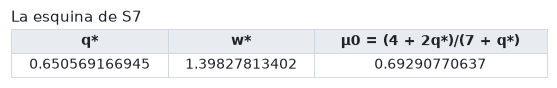

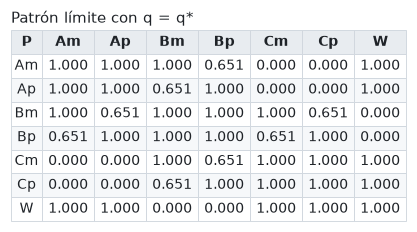

In [5]:
def f_e(q, w):
    # Las dos condiciones de neutralidad del modelo límite (Apéndice A de O'Keeffe).
    f = -2 * q**2 * w**2 - 4 * q**2 * w - 3 * q**2 - 2 * q + 4 * w + 1
    e = -q**2 * w**2 + q**2 - 2 * q * w**2 + 6 * q - w**2 + 1
    return f, e


def esquina(dps=50):
    # (q*, w*, μ0): punto donde los dos dipolos del modelo límite son exactamente neutros.
    with mp.workdps(dps):
        q, w = mp.findroot(f_e, (mp.mpf("0.65"), mp.mpf("1.4")))
        return q, w, (4 + 2 * q) / (7 + q)


def patron_limite(q):
    # Patrón límite: 1 completo, q adelgazado, 0 vacío (orden Am, Ap, Bm, Bp, Cm, Cp, W).
    filas = [
        [1, 1, 1, q, 0, 0, 1],
        [1, 1, q, 1, 0, 0, 1],
        [1, q, 1, 1, 1, q, 0],
        [q, 1, 1, 1, q, 1, 0],
        [0, 0, 1, q, 1, 1, 1],
        [0, 0, q, 1, 1, 1, 1],
        [1, 1, 0, 0, 1, 1, 1],
    ]
    P = []
    for fila in filas:
        P.append([mp.mpf(v) for v in fila])
    return P


q_estrella, w_estrella, mu_cero = esquina(30)
assert mu_cero == s7.esquina(30)[2]
mostrar_tabla(["q*", "w*", "μ0 = (4 + 2q*)/(7 + q*)"],
              [[mp.nstr(q_estrella, 12), mp.nstr(w_estrella, 12), mp.nstr(mu_cero, 12)]],
              titulo="La esquina de S7")

filas = []
for nombre, fila in zip(NOMBRES, patron_limite(q_estrella)):
    textos = [nombre]
    for valor in fila:
        textos.append(f"{float(valor):.3f}")
    filas.append(textos)
mostrar_tabla(["P"] + NOMBRES, filas, titulo="Patrón límite con q = q*")

**El costo de la cercanía a la esquina.** Cerca de $(q^*, w^*)$ el margen de estabilidad de los modos de
cluster es diminuto (O'Keeffe trabaja a $6\cdot 10^{-19}$ de la neutralidad), y eso es lo que encarece
pasar a un grafo con $n$ finito (sección 5). Para tener un grafo chico hay que **resignar algo de
$\mu$ a cambio de margen**. Además, la fórmula perturbativa de O'Keeffe ($q = q^* - t$ más una
corrección de orden $h$) pierde mucho $\mu$ cuando $h$ no es infinitesimal. Por eso no la usamos:
fijamos $h$ y buscamos las densidades **óptimas** para un margen dado.

**SDP interno.** Con $x$ y $\varphi$ fijos, maximizar $\min_a d_a$ sobre las densidades $P$ es un
problema convexo:
- $0 \le P \le 1$ simétrica, $P_{aa} = 1$, $P_{ab} = 0$ en los pares sin links (A–C, B–W);
- $\sum_b P_{ab}x_b \ge \tau$ para todo $a$, y se maximiza $\tau$ (en el código es la variable `t`,
  que no tiene relación con el $t$ de O'Keeffe);
- $F(P) = 0$ y $c(P) \ge 10^{-3}$: son lineales en $P$;
- $Q^\top L(P)\, Q / h^2 \succeq \varepsilon I$, con $Q$ una base ortonormal de $\mathbf 1^\perp$: es
  lineal en $P$, así que es una restricción semidefinida.

Se divide por $h^2$ porque los modos de cluster son $O(h^2)$.

El **margen** $\varepsilon$ es lo que, en nuestra construcción, reemplaza al $t$ de O'Keeffe
(sección 4).

**El código** (copiado de `src/busqueda.py` y `src/enteros.py`). `sdp_interno` arma el problema con
`cvxpy` y lo resuelve con el solver CLARABEL. `fases_s7` y `prohibidos_s7` son la misma cuenta que en
`src/enteros.py`, escrita directamente para S7 (allá pasa por una clase genérica de familias).

In [6]:
SECTORES = [0, 0, 1, 1, 2, 2, 3]


def fases_s7(h, s):
    # φ = fase del sector (múltiplo de π/2) + h·s; W queda en 3π/2.
    desplazamientos = np.concatenate([s, [0.0]])
    return np.array(SECTORES) * np.pi / 2 + h * desplazamientos


def prohibidos_s7():
    # Pares sin links: sectores opuestos (A–C y B–W).
    prohibidos = np.zeros((7, 7), dtype=bool)
    for a in range(7):
        for b in range(7):
            if abs(SECTORES[a] - SECTORES[b]) == 2:
                prohibidos[a, b] = True
    return prohibidos


def base_perpendicular(m):
    # Base ortonormal (m × (m−1)) del ortogonal de (1, …, 1).
    Q, _ = np.linalg.qr(np.eye(m) - 1.0 / m)
    return Q[:, : m - 1]


def sdp_interno(x, phi, escala=1.0, margen=1e-6, margen_c=1e-3, prohibidos=None, solver="CLARABEL"):
    # Mayor μ sobre las densidades P con x y φ fijos. Devuelve (μ, P) o (None, None) si es infactible.
    m = len(x)
    diferencias = phi[:, None] - phi[None, :]
    senos = np.sin(diferencias)
    cosenos = np.cos(diferencias)
    pesos_L = np.outer(x, x) * cosenos
    np.fill_diagonal(pesos_L, 0)

    P = cp.Variable((m, m), symmetric=True)
    t = cp.Variable()
    K = cp.multiply(P, pesos_L)
    L = cp.diag(cp.sum(K, axis=1)) - K
    Q = base_perpendicular(m)
    restricciones = [
        P >= 0,
        P <= 1,
        cp.diag(P) == 1,
        P @ x >= t,
        cp.multiply(P, senos) @ x == 0,
        cp.multiply(P, cosenos) @ x >= margen_c,
        (Q.T @ L @ Q) / escala >> margen * np.eye(m - 1),
    ]
    if prohibidos is not None:
        restricciones.append(cp.multiply(P, prohibidos.astype(float)) == 0)
    problema = cp.Problem(cp.Maximize(t), restricciones)
    try:
        problema.solve(solver=solver)
    except cp.error.SolverError:
        return None, None
    if problema.status not in ("optimal", "optimal_inaccurate"):
        return None, None
    return float(t.value), np.array(P.value)


def mejor_P(x, h, s, margen):
    # SDP interno de S7 con L/h² ⪰ margen: (μ, P) o (None, None).
    return sdp_interno(x, fases_s7(h, s), escala=h**2, margen=margen, prohibidos=prohibidos_s7())


s_prueba = np.array([-1.0, 1.0, -1.3, 1.3, -1.0, 1.0])
assert np.allclose(fases_s7(0.03, s_prueba), enteros.fases_s7(0.03, s_prueba))
assert (prohibidos_s7() == enteros.prohibidos_s7()).all()

**Problema externo** (`src/enteros.py: optimizar_s7`). El SDP elige $P$ para $s$ fijo; los
desplazamientos $s$ de las seis mitades se eligen por fuera, con Nelder–Mead. Los tamaños se fijan
racionales desde el principio, $x = (k_A, \dots, k_A, k_W)/K$, porque así después no hay que
redondearlos. Con $(k_A, k_W) = (3, 5)$ queda $K = 6\cdot 3 + 5 = 23$, y $k_W/k_A = 1.67$ está cerca del
óptimo $(1 - 6a)/a = 1 + q^* \approx 1.65$. 

```text
optimizar_s7(x, h, ε):
    s0 ← (−1, 1, −w*, w*, −1, 1)                       # el ansatz de O'Keeffe
    objetivo(s) = −μ de mejor_P(x, h, s, ε)  (o +1 si el SDP es infactible)
    s ← Nelder–Mead(objetivo, s0)   (hasta 600 iteraciones, tolerancias 1e-5 en s y 1e-9 en μ)
    μ, P ← mejor_P(x, h, s, ε)
    devolver μ, s, P
```

**La plantilla que usamos** tiene $h = 0.03$, $\varepsilon = 10^{-3}$ y tamaños $(3, 5)$. Sale de la
Fase 0 (sección 4) y está guardada en `data/s7_curva.json`, con sus desplazamientos `s` y densidades `P`.
Acá la cargamos, volvemos a correr el SDP con esos $s$ (tiene que dar el mismo $\mu$) y medimos con
`reporte_plantilla` la plantilla guardada.

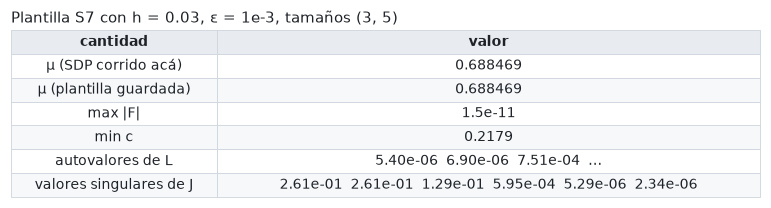

In [7]:
curva = cargar_json("s7_curva.json")


def fila_curva(h, margen, k=(3, 5)):
    # Fila de data/s7_curva.json con esos parámetros.
    for fila in curva:
        if fila["h"] == h and fila["margen"] == margen and tuple(fila["k"]) == tuple(k):
            return fila
    raise KeyError((h, margen, k))


H_PLANTILLA = 0.03
plantilla = fila_curva(H_PLANTILLA, 1e-3)
k_s7 = [3] * 6 + [5]
x_plantilla = np.array(k_s7) / sum(k_s7)
phi_plantilla = fases_s7(H_PLANTILLA, np.array(plantilla["s"]))
P_plantilla = np.array(plantilla["P"])

mu_sdp, _ = mejor_P(x_plantilla, H_PLANTILLA, np.array(plantilla["s"]), 1e-3)
reporte = reporte_plantilla(x_plantilla, phi_plantilla, P_plantilla)
assert np.isclose(reporte["mu"], plantillas.analizar(x_plantilla, phi_plantilla, P_plantilla)["mu"])

mostrar_tabla(["cantidad", "valor"], [
    ["μ (SDP corrido acá)", f"{mu_sdp:.6f}"],
    ["μ (plantilla guardada)", f"{reporte['mu']:.6f}"],
    ["max |F|", f"{reporte['max|F|']:.1e}"],
    ["min c", f"{reporte['min c']:.4f}"],
    ["autovalores de L", "  ".join(f"{v:.2e}" for v in reporte["autovalores L"][:3]) + "  …"],
    ["valores singulares de J", "  ".join(f"{v:.2e}" for v in reporte["singulares J"])],
], titulo="Plantilla S7 con h = 0.03, ε = 1e-3, tamaños (3, 5)")

- **μ = 0.6885:** está entre $11/16 = 0.6875$ y $\mu_0 = 0.6929$. El SDP corrido acá da el mismo valor.
- **max|F| ≠ 0:** el SDP no da un equilibrio exacto, sino uno con error del orden de la tolerancia
  del solver. En la sección 5 se corrige.
- **Valores singulares de J:** hay **tres** chicos ($6\cdot10^{-4}$, $5\cdot10^{-6}$ y $2\cdot10^{-6}$);
  los demás son $\gtrsim 0.1$. Son los modos casi neutros heredados de C4, y van a determinar el tamaño
  del grafo.

## 4. Fase 0: cuánto $\mu$ cuesta el margen

**$\varepsilon$ en lugar de $t$.** Ganar estabilidad cuesta $\mu$, y en eso las dos construcciones
coinciden; difieren en cómo se paga.
- **En O'Keeffe** la estabilidad se controla indirectamente. Se elige $q = q^* - t$ en la fórmula de las
  densidades (sección 3), y el gap sale proporcional a $t$, a cambio de $\mu_0(q^* - t) < \mu_0$.
- **Acá** se pide directamente $\lambda_{\min}(L)/h^2 \ge \varepsilon$, y el SDP elige **todas** las
  densidades libremente. Esta sección mide cuánto $\mu$ cuesta cada $\varepsilon$, que es la versión
  de la pregunta "cuánto cuesta $t$".
- **No hay un único $q$.** En la plantilla elegida (y en el grafo final, sección 7) las cuatro
  densidades cruzadas valen 0.614, 0.677, 0.612 y 0.677. No existe un $t$ del cual medir la distancia a
  $q^*$.
- **Por qué el SDP puede ganar $\mu$.** Con la escala de O'Keeffe (modo más débil $\sim h^2(t + h)$),
  pedir $\varepsilon$ equivale a $t + h \gtrsim \varepsilon$. Si $h \gg \varepsilon$, la apertura finita
  ya aporta el margen y no hace falta alejarse de la esquina en $q$. El SDP aprovecha esa libertad.

**Qué calcula** `scripts/curva_s7.py`. Para cada $h \in \{0.005, 0.01, 0.02, 0.03, 0.05\}$, cada margen
$\varepsilon \in \{10^{-5}, \dots, 10^{-2}\}$ y cada par de tamaños $(3,5), (11,18), (20,33)$, optimiza
S7 y mide su espectro. Cada punto es independiente, así que se reparten entre procesos. En
pseudocódigo:

```text
para cada (h, ε, (k_A, k_W)) en paralelo:
    x ← (k_A, …, k_A, k_W) / (6 k_A + k_W)
    μ, s, P ← optimizar_s7(x, h, ε)                      # sección 3
    si el SDP es infactible: descartar el punto
    φ ← fases_s7(h, s)
    guardar μ, s, P, autovalores normalizados de L, min c, condición de J
    # línea de base para la sección 5:
    pulir la plantilla y buscar en n = 10^4, 10^5, …, 10^16 el menor n con el que
    el redondeo ingenuo de los grados sigue dando un equilibrio estricto
```

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/curva_s7.py</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> server, CPU con 12 núcleos (no usa GPU)<br><b>Tiempo:</b> unos minutos (~80 min de CPU en total)<br><b>Salida:</b> <code>data/s7_curva.json (una fila por punto)</code></td></tr>
<tr><td align="left"><pre>OMP_NUM_THREADS=1 .venv/bin/python scripts/curva_s7.py --procesos 12</pre></td></tr>
</table>

`OMP_NUM_THREADS=1` evita que cada proceso abra sus propios hilos de BLAS y compitan entre sí.

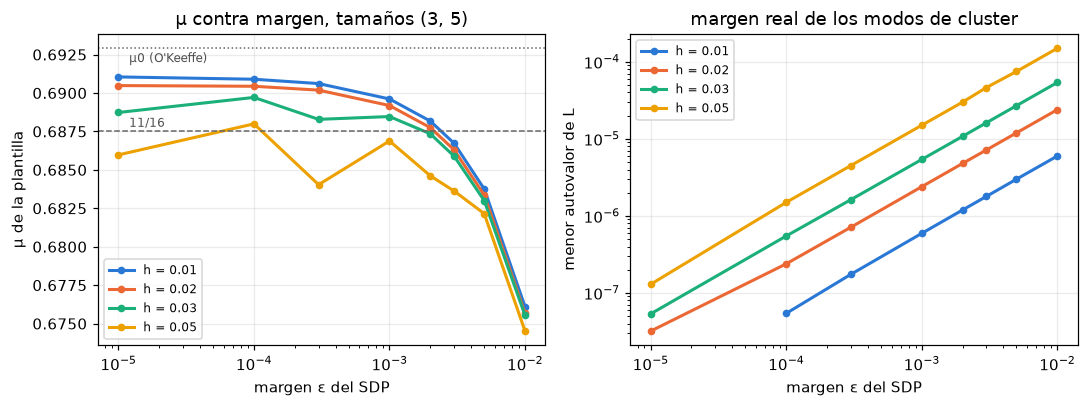

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
for color, h in zip(COLORES, [0.01, 0.02, 0.03, 0.05]):
    filas = sorted([f for f in curva if f["h"] == h and tuple(f["k"]) == (3, 5)], key=lambda f: f["margen"])
    margenes = [f["margen"] for f in filas]
    ejes[0].plot(margenes, [f["mu"] for f in filas], "o-", color=color, lw=2, ms=4, label=f"h = {h}")
    positivos = [f for f in filas if f["autovalores"][0] > 0]     # con ε muy chico el SDP puede dar ≤ 0 (ruido)
    ejes[1].plot([f["margen"] for f in positivos], [f["autovalores"][0] for f in positivos], "o-", color=color,
                 lw=2, ms=4, label=f"h = {h}")
ejes[0].axhline(11 / 16, color="0.4", lw=1, ls="--")
ejes[0].text(1.2e-5, 11 / 16 + 3e-4, "11/16", color="0.3", fontsize=8)
ejes[0].axhline(float(mu_cero), color="0.4", lw=1, ls=":")
ejes[0].text(1.2e-5, float(mu_cero) - 9e-4, "μ0 (O'Keeffe)", color="0.3", fontsize=8)
ejes[0].set(xscale="log", xlabel="margen ε del SDP", ylabel="μ de la plantilla", title="μ contra margen, tamaños (3, 5)")
ejes[1].set(xscale="log", yscale="log", xlabel="margen ε del SDP", ylabel="menor autovalor de L",
            title="margen real de los modos de cluster")
for eje in ejes:
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.**
- $\mu$ baja al subir el margen $\varepsilon$, y baja más rápido cuanto más grande es $h$. La curva es
  ruidosa porque Nelder–Mead no siempre encuentra el óptimo en $s$ (sobre todo con $h = 0.05$).
- El menor autovalor de $L$ crece como $\sim \varepsilon h^2$.
- Hay una ventana con $\mu > 11/16$ y margen apreciable. La plantilla elegida ($h = 0.03$,
  $\varepsilon = 10^{-3}$) tiene $\mu = 0.6885$. Ahí $h$ es 30 veces más grande que $\varepsilon$: el
  margen lo aporta la apertura de los pares, sin necesidad de un $t$.

## 5. De la plantilla a datos enteros, y por qué es difícil

**Datos enteros.** Un grafo concreto se describe con:
- tamaños $n_a = k_a g$ (6 mitades de $3g$ vértices y W de $5g$, así que $n = 23g$);
- grados $d_{ab}$: cuántos vecinos tiene **cada** vértice de $a$ en $b$.

Hay dos restricciones:
- **contar los links entre $a$ y $b$ desde los dos lados** da $n_a d_{ab} = n_b d_{ba}$;
- cada cluster es un clique: $d_{aa} = n_a - 1$.

Para que $n_a d_{ab} = n_b d_{ba}$ tenga solución, $d_{ab}$ tiene que ser múltiplo de
$k_b/\mathrm{mcd}(k_a, k_b)$. La plantilla del grafo es $x_a = n_a/n$, $P_{ab} = d_{ab}/n_b$, y
$\mu = (\delta + 1)/n$ con $\delta = \min_a \sum_b d_{ab}$.

**El redondeo ingenuo** toma $d_{ab}$ = el múltiplo permitido más cercano a $P_{ab} n_b$. El error en
las densidades es $\sim 1/n$.

**El código** (copiado de `src/enteros.py`): tamaños, el paso permitido, el redondeo ingenuo, la
plantilla exacta de los datos enteros (con `Fraction`) y el $\mu$ exacto.

In [9]:
def tamanos_enteros(k, g):
    # n_a = k_a·g.
    return [int(ka) * g for ka in k]


def tamanos_exactos(k):
    # x_a = k_a/K como Fraction.
    K = sum(int(ka) for ka in k)
    return [Fraction(int(ka), K) for ka in k]


def paso_grado(k, a, b):
    # d_ab tiene que ser múltiplo de k_b/mcd(k_a, k_b) para que n_a d_ab = n_b d_ba.
    return int(k[b]) // gcd(int(k[a]), int(k[b]))


def grados_ingenuos(x, P, k, g):
    # Redondea P_ab·n_b al múltiplo permitido más cercano (para a < b) y completa por simetría.
    m = len(k)
    n_a = tamanos_enteros(k, g)
    d = [[0] * m for _ in range(m)]
    for a in range(m):
        d[a][a] = n_a[a] - 1
        for b in range(a + 1, m):
            paso = paso_grado(k, a, b)
            j = int(mp.nint(P[a][b] * n_a[b] / paso))
            j = max(0, min(j, n_a[b] // paso))
            d[a][b] = j * paso
            d[b][a] = d[a][b] * n_a[a] // n_a[b]
    return d


def plantilla_entera(k, g, d):
    # (x, P) exactos como Fraction: x_a = n_a/n, P_ab = d_ab/n_b.
    n_a = tamanos_enteros(k, g)
    n = sum(n_a)
    x = [Fraction(na, n) for na in n_a]
    P = []
    for a in range(len(k)):
        fila = []
        for b in range(len(k)):
            fila.append(Fraction(d[a][b], n_a[b]))
        P.append(fila)
    return x, P


def mu_entero(k, g, d):
    # μ = (δ + 1)/n exacto, con δ el grado mínimo.
    n = sum(tamanos_enteros(k, g))
    grados = []
    for fila in d:
        grados.append(sum(fila))
    return Fraction(min(grados) + 1, n)

**El pliegue.** $J$ tiene tres valores singulares $\sigma_k$ muy chicos (sección 3).
- **Forma normal.** En la dirección blanda $k$, el equilibrio de los datos perturbados es raíz de
  $$\sigma_k\, y + \tfrac{c}{2}\, y^2 + \rho_k = 0,$$
  donde $\rho_k$ es el residuo de esa ecuación. Es la forma normal de una silla-nodo: el mínimo
  estricto vive al lado de un pliegue.
- **Existencia y estabilidad.** Hay solución solo si $2c\rho_k \le \sigma_k^2$, y su estabilidad es
  $\sqrt{\sigma_k^2 - 2c\rho_k}$.
- **Costo del redondeo ingenuo.** Como $\rho_k \sim 1/n$, hace falta $n \gtrsim c/\sigma_k^2$. La
  constante depende de cuánto pesa cada error de redondeo en la dirección blanda, así que la escala
  exacta se mide: para esta plantilla el redondeo ingenuo necesita $n \approx 10^9$.
- **Si el redondeo pasa el pliegue, el equilibrio desaparece:** Newton se estanca o las fases saltan
  lejos de las de S7.

Antes de redondear hay que **pulir** la plantilla, y después de redondear hay que **evaluar** el
resultado. Las dos funciones de `src/enteros.py` que lo hacen trabajan en alta precisión con varias
funciones auxiliares, así que van en pseudocódigo:

```text
pulir(x, φ, P):                         # el SDP deja F ≈ 1e-9: corregirlo antes de redondear
    pares ← {(a, b) : a < b, 0 < P_ab < 1}           # los completos y vacíos quedan fijos
    F es lineal en P:  F(P + Δ) = F(P) + A Δ,  con A[a, (a,b)] = x_b sin(φ_a − φ_b)
                                                    y A[b, (a,b)] = −x_a sin(φ_a − φ_b)
    Δ ← solución de mínima norma de A Δ = −F         # Δ = Aᵀ (A Aᵀ)⁻¹ (−F), con 60 dígitos
    devolver x (Fraction), φ, P + Δ                  # ahora F(φ) = 0 exacto

evaluar_enteros(k, g, d, φ0, h):
    x, P ← plantilla_entera(k, g, d)                 # Fraction
    φ ← Newton para F(φ) = 0 desde φ0, con 40 dígitos (si no converge: no es estricto)
    estricto ← λ_min(L) > 0  y  min c > 0  y  max|F| < 1e-20  y  max|φ − φ0| < h/4
    devolver estricto, λ_min(L), min c, cuánto se movieron las fases
```

La última condición pide que las fases sigan cerca de las de S7: si el redondeo pasa el pliegue, Newton
puede encontrar otro equilibrio lejos, que no es el que queremos. Probamos el redondeo ingenuo con
$n = 3\cdot 10^7$ y $n = 10^9$:

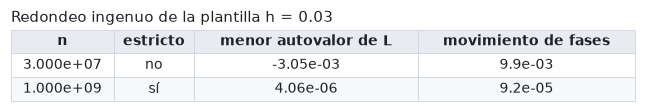

In [10]:
x_exacto, phi_pulida, P_pulida = pulir(tamanos_exactos(k_s7), phi_plantilla, P_plantilla)

filas = []
for n_objetivo in [3e7, 1e9]:
    g = int(round(n_objetivo / sum(k_s7)))
    d = grados_ingenuos(x_exacto, P_pulida, k_s7, g)
    assert d == enteros.grados_ingenuos(x_exacto, P_pulida, k_s7, g)
    evaluacion = evaluar_enteros(k_s7, g, d, phi_pulida, H_PLANTILLA)
    filas.append([f"{sum(k_s7) * g:.3e}", si_no(evaluacion["ok"]), f"{evaluacion['menor autovalor']:.2e}",
                  f"{evaluacion['movimiento fases']:.1e}"])
mostrar_tabla(["n", "estricto", "menor autovalor de L", "movimiento de fases"], filas,
              titulo="Redondeo ingenuo de la plantilla h = 0.03")

Con $n = 3\cdot 10^7$ el redondeo ingenuo da un equilibrio **inestable** (autovalor negativo de $L$).
Con $n = 10^9$ funciona.

## 6. Fase 1: redondeo por reticulado

**Idea.** El redondeo ingenuo elige cada $d_{ab}$ por separado. Pero hay varios enteros libres y solo
3 ecuaciones blandas que hay que cuidar. Se pueden elegir los enteros **en conjunto** para que el
residuo blando quede mucho más chico que $1/n$.

**Cuántos enteros libres hay.** Hay un entero por par de clusters $a < b$: $d_{ba}$ queda fijado por
$n_a d_{ab} = n_b d_{ba}$, y $d_{aa} = n_a - 1$. De los 21 pares:
- 6 son de sectores opuestos (A–C y B–W) y quedan vacíos;
- los que el SDP dejó en 0 o en 1 quedan fijos (vacío o completo): no hay nada que redondear;
- los demás, con $0 < P_{ab} < 1$, son los libres (`pares_libres`, con tolerancia $10^{-7}$).

Cuántos quedan depende de la plantilla. En la de $h = 0.03$ (la de este grafo) el SDP deja 6 pares
vecinos en 1 (Am–Ap, Am–Bm, Bm–Bp, Bp–Cp, Cm–Cp, Cp–W) y quedan **9 libres**: los 4 cruzados (Am–Bp,
Ap–Bm, Bm–Cp, Bp–Cm) y 5 vecinos que bajan un poco de 1 (Ap–Bp, Bm–Cm, Am–W, Ap–W, Cm–W). En las
plantillas con $h \le 0.02$ el SDP no deja ningún vecino en 1 y quedan **15 libres**.

**Reducción de Lyapunov–Schmidt.** En la plantilla se descompone $J = U S V^\top$.
- Las direcciones rígidas (valores singulares grandes) están bien condicionadas: se resuelven
  exactamente por Newton, $U_r^\top F(\varphi^* + V_r z) = 0$.
- Queda el **residuo blando** $g = U_b^\top F$, de 3 componentes. Está bien definido aunque no haya
  equilibrio, y es casi lineal en los grados.

**Newton entero.** En cada paso:
- se calcula $g$ y su derivada respecto de los $m$ grados libres (diferencias finitas en alta
  precisión);
- se busca $u \in \mathbb Z^{m}$ con $\mathrm{d}g \cdot u \approx -g$, midiendo cada componente en
  unidades de su tolerancia $\sigma_k^2$ (la distancia al pliegue);
- además $u$ tiene que ser chico (radio $\sim 3$–$100$), para no mover las densidades y no romper las
  ecuaciones rígidas.

El ciclo completo (`src/enteros.py: redondeo_reticulado`) en pseudocódigo:

```text
redondeo_reticulado(x, P, φ, h, k, g):
    pares ← los pares con 0 < P_ab < 1                 # m = 9 con h = 0.03
    U_b, U_r, V_b, V_r, σ ← SVD de J en la plantilla, separando los 3 valores singulares más chicos
    tolerancias ← σ²
    d0 ← grados_ingenuos(x, P, k, g);   mejor ← (d0, evaluar_enteros(d0))
    para cada radio en (3, 10, 30, 100):
        d ← d0
        repetir 4 veces:
            # residuo blando y su derivada (60 dígitos):
            resolver por Newton las ecuaciones rígidas U_rᵀ F(φ + V_r z) = 0   →  φ_red
            g ← U_bᵀ F(φ_red);   dg ← derivada de g respecto de cada P_ab (diferencias finitas)
            d ← corregir_grados(d, pares, g, dg, radio, tolerancias)        # un paso de Newton entero
            evaluar d en exacto desde φ_red (evaluar_enteros) y guardar si es el mejor
    devolver el mejor d y su evaluación
```

**El problema entero es un problema de vector más cercano en un reticulado.** Hay que encontrar
$u \in \mathbb Z^m$ cerca de un objetivo real $u_0$ (la solución de mínimos cuadrados de
$\mathrm{d}g\cdot u = -g$) tal que las formas lineales $A(u - u_0)$ sean casi 0.
- **Encaje de Kannan:** el reticulado tiene filas $(e_i/r,\ \text{peso}\cdot A_{:,i})$, donde $r$ es el
  radio. Un vector del reticulado cerca de $(u_0/r,\ \text{peso}\cdot A u_0)$ es un entero cerca de
  $u_0$ **y** con las formas casi anuladas.
- Se reduce la base con **LLL** (Lenstra–Lenstra–Lovász): una base del mismo reticulado con vectores
  cortos y casi ortogonales.
- Se aproxima el vector más cercano con el **plano más cercano de Babai**: con la base reducida,
  se redondea el coeficiente de cada vector de Gram–Schmidt, del último al primero.

**El código** (copiado de `src/reticulado.py` y `src/enteros.py`): Gram–Schmidt, LLL, Babai, el encaje
de Kannan (`enteros_cercanos`) y el paso de Newton entero (`corregir_grados`).

In [11]:
def gram_schmidt(B):
    # Ortogonalización sin normalizar: (B*, μ) con B_i = B*_i + Σ_{j<i} μ_ij B*_j.
    n = B.shape[0]
    ortogonales = np.zeros_like(B)
    mu = np.zeros((n, n))
    for i in range(n):
        vector = B[i].copy()
        for j in range(i):
            mu[i, j] = B[i] @ ortogonales[j] / (ortogonales[j] @ ortogonales[j])
            vector -= mu[i, j] * ortogonales[j]
        ortogonales[i] = vector
    return ortogonales, mu


def lll(B, delta=0.99):
    # Base LLL-reducida del reticulado generado por las filas de B.
    B = np.array(B, dtype=float)
    n = B.shape[0]
    ortogonales, mu = gram_schmidt(B)
    k = 1
    while k < n:
        for j in range(k - 1, -1, -1):
            q = round(mu[k, j])
            if q != 0:
                B[k] -= q * B[j]
                ortogonales, mu = gram_schmidt(B)
        lovasz = (delta - mu[k, k - 1] ** 2) * (ortogonales[k - 1] @ ortogonales[k - 1])
        if ortogonales[k] @ ortogonales[k] >= lovasz:
            k += 1
        else:
            B[[k, k - 1]] = B[[k - 1, k]]
            ortogonales, mu = gram_schmidt(B)
            k = max(k - 1, 1)
    return B


def babai(B, objetivo):
    # Coeficientes enteros c tales que c·B está cerca de objetivo (plano más cercano de Babai).
    ortogonales, _ = gram_schmidt(B)
    resto = np.array(objetivo, dtype=float)
    coeficientes = np.zeros(B.shape[0])
    for i in range(B.shape[0] - 1, -1, -1):
        c = round(resto @ ortogonales[i] / (ortogonales[i] @ ortogonales[i]))
        resto -= c * B[i]
        coeficientes[i] = c
    return coeficientes


def enteros_cercanos(formas, objetivo, radio, peso=1e3):
    # u ∈ Z^m con |u − objetivo| del orden de radio y formas·(u − objetivo) ≈ 0 (encaje de Kannan).
    formas = np.asarray(formas, dtype=float)
    formas = formas / max(np.abs(formas).max(), 1e-300)
    m = formas.shape[1]
    factor = peso * radio
    B = np.hstack([np.eye(m) / radio, factor * formas.T])
    objetivo = np.asarray(objetivo, dtype=float)
    vector_objetivo = np.concatenate([objetivo / radio, factor * formas @ objetivo])
    reducida = lll(B)
    coeficientes = babai(reducida, vector_objetivo)
    return np.round((coeficientes @ reducida)[:m] * radio)


def corregir_grados(d, k, g, pares, residuo, derivada, radio, tolerancias):
    # Un paso de Newton entero: grados cuyo cambio anula (en lo posible) el residuo blando.
    n_a = tamanos_enteros(k, g)
    pasos = []
    actuales = []
    escalas = []
    for a, b in pares:
        paso = paso_grado(k, a, b)
        pasos.append(paso)
        actuales.append(d[a][b] // paso)
        escalas.append(paso / n_a[b])
    pesos = 1 / np.asarray(tolerancias)
    formas = pesos[:, None] * derivada * np.array(escalas)[None, :]
    objetivo = np.linalg.lstsq(formas, -pesos * residuo, rcond=None)[0]
    u = enteros_cercanos(formas, objetivo, radio)
    nuevos = [fila[:] for fila in d]
    for i, (a, b) in enumerate(pares):
        j = max(0, min(actuales[i] + int(u[i]), n_a[b] // pasos[i]))
        nuevos[a][b] = j * pasos[i]
        nuevos[b][a] = nuevos[a][b] * n_a[a] // n_a[b]
    return nuevos

**Un ejemplo de juguete** del encaje de Kannan, con el mismo tamaño que nuestro problema: 3 formas
lineales al azar sobre $\mathbb Z^{9}$ y un objetivo real al azar. Comparamos redondear cada
coordenada por separado (lo que hace el redondeo ingenuo) con `enteros_cercanos`. Lo que importa es
$|A(u - u_0)|$, que en el problema real es el residuo blando.

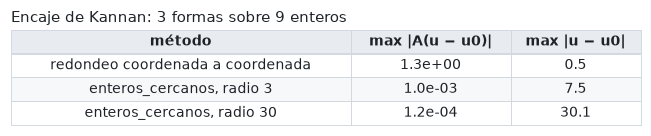

In [12]:
rng = np.random.default_rng(0)
A_juguete = rng.standard_normal((3, 9))
objetivo_juguete = rng.uniform(-50, 50, 9)
filas = []
for nombre, u in [("redondeo coordenada a coordenada", np.round(objetivo_juguete)),
                  ("enteros_cercanos, radio 3", enteros_cercanos(A_juguete, objetivo_juguete, 3)),
                  ("enteros_cercanos, radio 30", enteros_cercanos(A_juguete, objetivo_juguete, 30))]:
    filas.append([nombre, f"{np.abs(A_juguete @ (u - objetivo_juguete)).max():.1e}",
                  f"{np.abs(u - objetivo_juguete).max():.1f}"])
assert (enteros_cercanos(A_juguete, objetivo_juguete, 3) == reticulado.enteros_cercanos(A_juguete, objetivo_juguete, 3)).all()
mostrar_tabla(["método", "max |A(u − u0)|", "max |u − u0|"], filas,
              titulo="Encaje de Kannan: 3 formas sobre 9 enteros")

Redondear coordenada a coordenada deja $|A(u - u_0)| \sim 1$. El reticulado lo baja varios órdenes de
magnitud a cambio de alejarse un poco más del objetivo, y cuanto más grande es el radio, más chico
queda el residuo. En el problema real eso es lo que permite esquivar el pliegue.

Corremos ahora el redondeo por reticulado de `src/` (que usa estas mismas funciones) para el mismo caso
de la sección 5 ($h = 0.03$, $n = 3\cdot 10^7$). Tarda unos segundos.

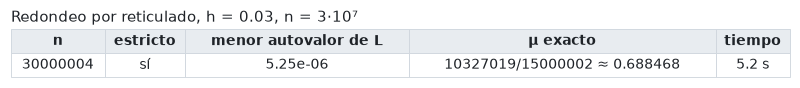

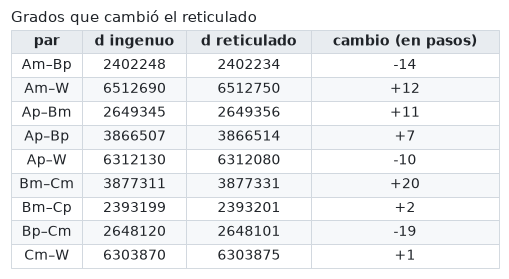

In [13]:
g_chico = int(round(3e7 / sum(k_s7)))
inicio = time.time()
d_reticulado, evaluacion = redondeo_reticulado(x_exacto, P_pulida, phi_pulida, H_PLANTILLA, k_s7, g_chico)
segundos = time.time() - inicio
mu_reticulado = mu_entero(k_s7, g_chico, d_reticulado)
mostrar_tabla(["n", "estricto", "menor autovalor de L", "μ exacto", "tiempo"],
              [[sum(k_s7) * g_chico, si_no(evaluacion["ok"]), f"{evaluacion['menor autovalor']:.2e}",
                f"{mu_reticulado} ≈ {float(mu_reticulado):.6f}", f"{segundos:.1f} s"]],
              titulo="Redondeo por reticulado, h = 0.03, n = 3·10⁷")

d_ingenuo = grados_ingenuos(x_exacto, P_pulida, k_s7, g_chico)
filas = []
for a in range(7):
    for b in range(a + 1, 7):
        if d_reticulado[a][b] != d_ingenuo[a][b]:
            cambio = (d_reticulado[a][b] - d_ingenuo[a][b]) // paso_grado(k_s7, a, b)
            filas.append([f"{NOMBRES[a]}–{NOMBRES[b]}", d_ingenuo[a][b], d_reticulado[a][b], f"{cambio:+d}"])
mostrar_tabla(["par", "d ingenuo", "d reticulado", "cambio (en pasos)"], filas,
              titulo="Grados que cambió el reticulado")

Bastan cambios de unas pocas unidades en algunos grados, de un total de $\sim 10^7$, para que el
equilibrio pase de inestable a estricto.

**El script de la Fase 1** (`scripts/s7_entero.py`) repite esto para tres plantillas y una grilla de $n$:

```text
para cada plantilla (h ∈ {0.03, 0.02, 0.01}, ε = 1e-3, tamaños (3, 5)) y cada n ∈ {1e6, 3e6, …, 1e9}, en paralelo:
    g ← round(n / 23)
    x, φ, P ← pulir(plantilla)
    ingenuo ← evaluar_enteros(grados_ingenuos(x, P, k, g))
    d, reticulado ← redondeo_reticulado(x, P, φ, h, k, g)
    guardar: estricto (ingenuo y reticulado), λ_min(L), μ exacto, grados d, fases
```

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/s7_entero.py</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU (server con 12 núcleos o local con 8)<br><b>Tiempo:</b> unos 4 min de CPU en total<br><b>Salida:</b> <code>data/s7_enteros.json</code></td></tr>
<tr><td align="left"><pre># server
OMP_NUM_THREADS=1 .venv/bin/python scripts/s7_entero.py --procesos 12
# local
.venv/bin/python scripts/s7_entero.py --procesos 8</pre></td></tr>
</table>

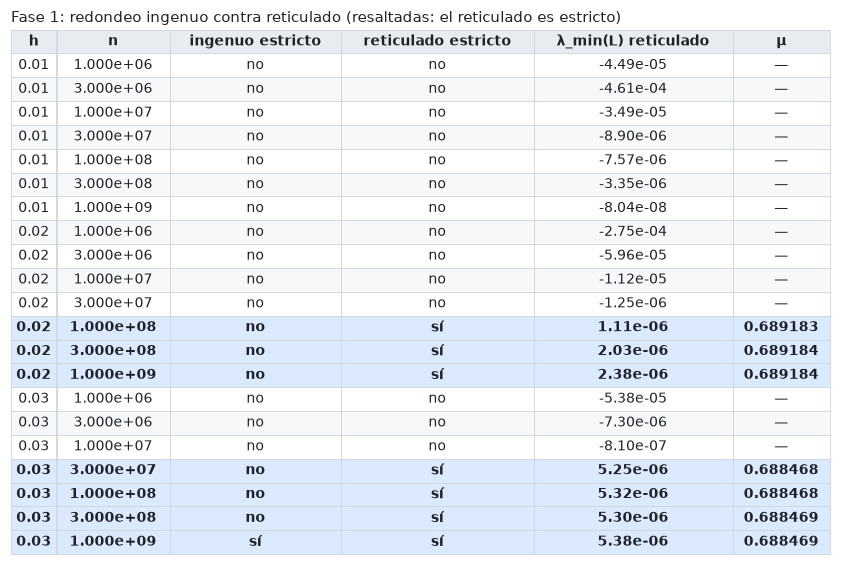

In [14]:
filas_enteras = cargar_json("s7_enteros.json")
filas = []
resaltadas = []
for i, r in enumerate(filas_enteras):
    filas.append([f"{r['h']:.2f}", f"{r['n']:.3e}", si_no(r["ingenuo_ok"]), si_no(r["reticulado_ok"]),
                  f"{r['menor_autovalor']:.2e}", f"{r['mu']:.6f}" if r["reticulado_ok"] else "—"])
    if r["reticulado_ok"]:
        resaltadas.append(i)
mostrar_tabla(["h", "n", "ingenuo estricto", "reticulado estricto", "λ_min(L) reticulado", "μ"], filas,
              titulo="Fase 1: redondeo ingenuo contra reticulado (resaltadas: el reticulado es estricto)",
              resaltar=resaltadas)

**Lectura.**
- El reticulado baja el $n$ necesario en uno o dos órdenes de magnitud:
  - $h = 0.03$: de $10^9$ a $3\cdot10^7$;
  - $h = 0.02$: de más de $10^9$ a $10^8$, con $\mu = 0.689183$.
- $h = 0.01$ tiene más $\mu$ pero menos margen, y no alcanza ni con $n = 10^9$.
- **Escala (heurística):** el ingenuo necesita $n \sim \sigma^{-2}$, y el reticulado con $m$ enteros
  libres y 3 restricciones $n \sim \sigma^{-(1 + 3/m)}$: $\sigma^{-1.33}$ con los 9 de $h = 0.03$ y
  $\sigma^{-1.2}$ con los 15 de $h \le 0.02$. Con más enteros libres por restricción se acerca a
  $\sigma^{-1}$. Esa es la idea del "camino B" (sección 11).

## 7. Fase 2: el grafo, un blow-up circulante

Falta un grafo en el que **cada** vértice de $a$ tenga **exactamente** $d_{ab}$ vecinos en $b$. Con eso
las fases de los clusters son un equilibrio exacto del grafo, porque la velocidad de un vértice de $a$
es $-nF_a = 0$. Usamos un blow-up circulante, que generaliza el k-spinning de Canale:

- **Vértices:** el cluster $a$ tiene $k_a$ bloques y cada bloque es una copia de $\mathbb Z_g$. El
  vértice es $(a, i, v)$, con $i < k_a$ y $v \in \mathbb Z_g$.
- **Dentro de un cluster:** clique.
- **Entre clusters $a < b$:** $(a, i, v) \sim (b, j, v + s \bmod g)$ para $s \in \{0, \dots, t_{ij} - 1\}$:
  cada vértice se une con un intervalo de $t_{ij}$ vértices consecutivos del otro bloque (como en Canale).
- **Grados:** un vértice $(a, i, \cdot)$ tiene $\sum_j t_{ij}$ vecinos en $b$, y un vértice
  $(b, j, \cdot)$ tiene $\sum_i t_{ij}$ vecinos en $a$. Entonces hace falta una tabla $t$ de
  $k_a \times k_b$ con filas que sumen $d_{ab}$, columnas que sumen $d_{ba}$ y entradas en $[0, g]$.
  Es un problema de transporte.

**Solución explícita del transporte:**
- todas las entradas valen $\text{base}$ o $\text{base} + 1$, con $\text{base} = \lfloor k_a d_{ab}/(k_a k_b) \rfloor$;
- en la fila $i$, los "+1" van en las columnas $i e, \dots, ie + e - 1 \pmod{k_b}$, con
  $e = d_{ab} - k_b\,\text{base}$;
- recorridas en orden, las filas cubren las columnas de forma cíclica, así que cada columna recibe la
  misma cantidad de "+1".

No hace falta que $g$ sea múltiplo de nada. Ahí se ahorra el $D^2$ de O'Keeffe: el grafo tiene
$n = 23 g$ vértices, con $g$ libre.

**Lo que se publica:** $k$, $g$, los grados, las tablas y las fases. Son unos pocos KB, y con eso
cualquiera reconstruye el grafo.

**El código** (copiado de `src/blowup.py`): el índice del primer vértice de cada cluster, la tabla de
transporte, las tablas de todos los pares y la adyacencia densa (esta última solo sirve para $n$ chico).

In [15]:
def desplazamientos_cluster(k, g):
    # Índice del primer vértice de cada cluster (vértice (a, i, v) ↦ inicio_a + i·g + v).
    inicios = [0]
    for ka in k[:-1]:
        inicios.append(inicios[-1] + ka * g)
    return inicios


def tabla_transporte(d_ab, k_a, k_b, g):
    # Tabla t (k_a × k_b) con filas d_ab, columnas d_ba = k_a d_ab/k_b y entradas en {base, base + 1}.
    total = k_a * d_ab
    assert total % k_b == 0, "tiene que valer k_a d_ab = k_b d_ba"
    assert 0 <= d_ab <= k_b * g
    base = total // (k_a * k_b)
    extra_fila = d_ab - k_b * base
    t = [[base] * k_b for _ in range(k_a)]
    for i in range(k_a):
        for desplazamiento in range(extra_fila):
            t[i][(i * extra_fila + desplazamiento) % k_b] += 1
    return t


def tablas_bloques(k, g, d):
    # {(a, b): tabla t} para a < b.
    tablas = {}
    for a in range(len(k)):
        for b in range(a + 1, len(k)):
            tablas[(a, b)] = tabla_transporte(d[a][b], k[a], k[b], g)
    return tablas


def adyacencia_densa(k, g, d):
    # Matriz de adyacencia del blow-up (solo para n chico).
    n_a = tamanos_enteros(k, g)
    inicios = desplazamientos_cluster(k, g)
    W = np.zeros((sum(n_a), sum(n_a)))
    for a in range(len(k)):
        bloque = slice(inicios[a], inicios[a] + n_a[a])
        W[bloque, bloque] = 1 - np.eye(n_a[a])
    v = np.arange(g)
    for (a, b), t in tablas_bloques(k, g, d).items():
        for i in range(k[a]):
            for j in range(k[b]):
                origen = inicios[a] + i * g + v
                for s in range(t[i][j]):
                    destino = inicios[b] + j * g + (v + s) % g
                    W[origen, destino] = 1
                    W[destino, origen] = 1
    return W

Un ejemplo chico para verlo: $k = (1, 2, 3)$, $g = 5$ ($n = 30$), con grados elegidos a mano. Se arma
la adyacencia densa, se verifica que cada vértice tiene exactamente los grados pedidos y se dibuja la
matriz.

grados exactos en los 30 vértices


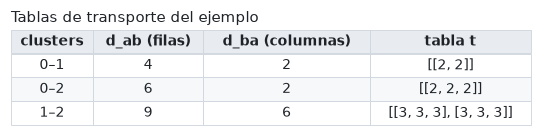

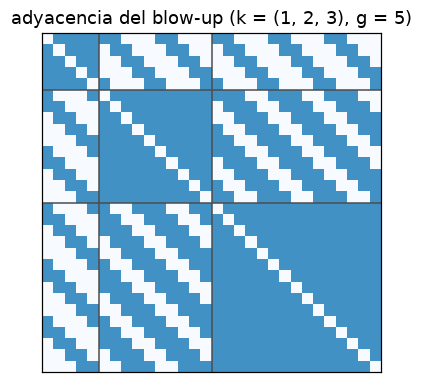

In [16]:
k_ejemplo = [1, 2, 3]
g_ejemplo = 5
d_ejemplo = [[4, 4, 6], [2, 9, 9], [2, 6, 14]]     # n_a d_ab = n_b d_ba con n = (5, 10, 15)
W_ejemplo = adyacencia_densa(k_ejemplo, g_ejemplo, d_ejemplo)
assert (W_ejemplo == blowup.adyacencia_densa(k_ejemplo, g_ejemplo, d_ejemplo)).all()
inicios = desplazamientos_cluster(k_ejemplo, g_ejemplo)
tamanos = tamanos_enteros(k_ejemplo, g_ejemplo)
for a in range(3):
    for b in range(3):
        cuentas = W_ejemplo[inicios[a]: inicios[a] + tamanos[a], inicios[b]: inicios[b] + tamanos[b]].sum(axis=1)
        assert (cuentas == d_ejemplo[a][b]).all()
print("grados exactos en los 30 vértices")

filas = []
for (a, b), t in tablas_bloques(k_ejemplo, g_ejemplo, d_ejemplo).items():
    filas.append([f"{a}–{b}", d_ejemplo[a][b], d_ejemplo[b][a], str(t)])
mostrar_tabla(["clusters", "d_ab (filas)", "d_ba (columnas)", "tabla t"], filas,
              titulo="Tablas de transporte del ejemplo")

fig, eje = plt.subplots(figsize=(4, 4))
eje.imshow(W_ejemplo, cmap="Blues", vmin=0, vmax=1.6)
for corte in inicios[1:]:
    eje.axhline(corte - 0.5, color="0.3", lw=1)
    eje.axvline(corte - 0.5, color="0.3", lw=1)
eje.set(title="adyacencia del blow-up (k = (1, 2, 3), g = 5)", xticks=[], yticks=[])
plt.show()

Las diagonales que se ven fuera de los bloques de cada cluster son los intervalos de desplazamientos
(matrices circulantes).

**El grafo real.** Cargamos la descripción compacta del grafo de $3\cdot 10^7$ vértices
(`data/grafos_s7.json`, producido en la sección 8) y mostramos sus grados $d_{ab}$ y la tabla $t$ de
un par con densidad intermedia.

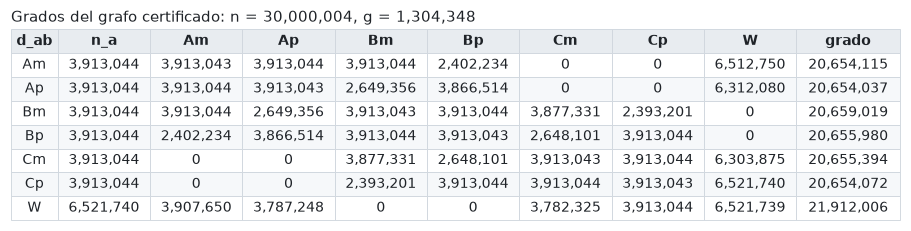

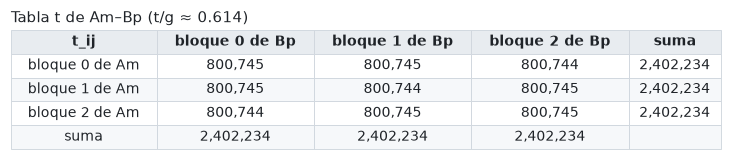

In [17]:
grafos = cargar_json("grafos_s7.json")
grafo_chico = min([f for f in grafos if f["redondeo"] == "reticulado"], key=lambda f: f["grafo"]["n"])
descripcion = grafo_chico["grafo"]
tamanos_reales = tamanos_enteros(descripcion["k"], descripcion["g"])

filas = []
for a, nombre in enumerate(NOMBRES):
    fila = [nombre, f"{tamanos_reales[a]:,}"]
    for valor in descripcion["grados"][a]:
        fila.append(f"{valor:,}")
    fila.append(f"{sum(descripcion['grados'][a]):,}")
    filas.append(fila)
mostrar_tabla(["d_ab", "n_a"] + NOMBRES + ["grado"], filas,
              titulo=f"Grados del grafo certificado: n = {descripcion['n']:,}, g = {descripcion['g']:,}")

clave = "0,3"
tabla = descripcion["tablas"][clave]
assert tabla == tabla_transporte(descripcion["grados"][0][3], 3, 3, descripcion["g"])
filas = []
for i, fila in enumerate(tabla):
    filas.append([f"bloque {i} de Am"] + [f"{t:,}" for t in fila] + [f"{sum(fila):,}"])
filas.append(["suma"] + [f"{sum(columna):,}" for columna in zip(*tabla)] + [""])
mostrar_tabla(["t_ij", "bloque 0 de Bp", "bloque 1 de Bp", "bloque 2 de Bp", "suma"], filas,
              titulo=f"Tabla t de Am–Bp (t/g ≈ {tabla[0][0] / descripcion['g']:.3f})")

**La tabla $d_{ab}$ no es simétrica, y no tiene por qué serlo.** La adyacencia sí es simétrica, pero $d_{ab}$
cuenta vecinos **por vértice**. Contando las aristas entre $a$ y $b$ desde cada lado tiene que dar lo mismo:
$$\#\text{aristas}(a, b) = n_a\, d_{ab} = n_b\, d_{ba},$$
así que $d_{ab} = d_{ba}$ solo si $n_a = n_b$. Acá los seis clusters de A, B y C tienen 3 bloques y W tiene 5,
por eso solo la fila y la columna de W difieren, en la proporción $d_{aW}/d_{Wa} = n_W/n_a = 5/3$. Lo simétrico
es la **densidad** del par, $d_{ab}/n_b = d_{ba}/n_a$ (los porcentajes de la figura de 7.1).

n_a·d_ab = n_b·d_ba en los 21 pares


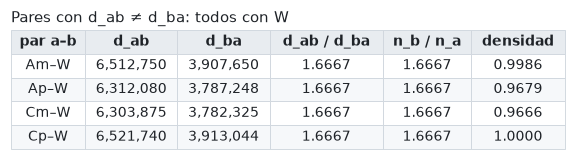

In [18]:
n = tamanos_reales
d = descripcion["grados"]
for a in range(len(n)):
    for b in range(len(n)):
        assert n[a] * d[a][b] == n[b] * d[b][a], (NOMBRES[a], NOMBRES[b])
print(f"n_a·d_ab = n_b·d_ba en los {len(n) * (len(n) - 1) // 2} pares")

filas = []
for a in range(len(n)):
    for b in range(a + 1, len(n)):
        if d[a][b] != d[b][a]:
            filas.append([f"{NOMBRES[a]}–{NOMBRES[b]}", f"{d[a][b]:,}", f"{d[b][a]:,}",
                          f"{d[a][b] / d[b][a]:.4f}", f"{n[b] / n[a]:.4f}", f"{d[a][b] / n[b]:.4f}"])
mostrar_tabla(["par a–b", "d_ab", "d_ba", "d_ab / d_ba", "n_b / n_a", "densidad"], filas,
              titulo="Pares con d_ab ≠ d_ba: todos con W")

### 7.1 Cómo se ve el grafo

Con $3\cdot 10^7$ vértices no se puede dibujar la matriz de adyacencia, pero sí **a escala**: cada
bloque $\mathbb Z_g$ se parte en $F$ franjas de $L = \lfloor g/F \rfloor$ vértices consecutivos, y cada
píxel muestra la fracción de pares unidos entre dos franjas.

**La densidad de un píxel se calcula exacta.** En un bloque circulante con intervalo $\{0, \dots, t-1\}$,
el vértice $v$ de la franja $p$ y el vértice $w$ de la franja $q$ están unidos si $(w - v) \bmod g < t$.
La cantidad de pares $(v, w)$ con $w - v = \delta$ es $L - |\delta - (q-p)L|$ (una "carpa"), así que la
densidad solo depende de $q - p$:
$$\text{densidad}(p, q) = \frac{1}{L^2}\sum_{|\delta - (q-p)L| < L} \big(L - |\delta - (q-p)L|\big)\,
[\,(\delta \bmod g) < t\,].$$

**El código** (copiado de `scripts/visualizar_grafo.py`), comparado con el promedio por franjas de la
matriz circulante densa en un caso chico:

In [19]:
def densidad_circulante(t, g, franjas):
    # Densidad por píxel (franjas × franjas) del bloque circulante v ~ v + s, s < t, en Z_g.
    largo = g // franjas
    desfase = np.arange(-largo + 1, largo)
    peso = largo - np.abs(desfase)
    por_diferencia = np.zeros(franjas)
    for diferencia in range(franjas):
        delta = diferencia * largo + desfase
        por_diferencia[diferencia] = (peso * ((delta % g) < t)).sum() / largo**2
    p, q = np.meshgrid(np.arange(franjas), np.arange(franjas), indexing="ij")
    return por_diferencia[(q - p) % franjas]


t_prueba, g_prueba, franjas_prueba = 23, 60, 6
circulante = np.zeros((g_prueba, g_prueba))
for v in range(g_prueba):
    for s in range(t_prueba):
        circulante[v, (v + s) % g_prueba] = 1
largo_prueba = g_prueba // franjas_prueba
promedio = circulante.reshape(franjas_prueba, largo_prueba, franjas_prueba, largo_prueba).mean(axis=(1, 3))
assert np.allclose(promedio, densidad_circulante(t_prueba, g_prueba, franjas_prueba))
print("densidad por franjas exacta en el caso de prueba")

densidad por franjas exacta en el caso de prueba


El resto del script arma la imagen bloque por bloque (cliques en 1, pares opuestos en 0, y
`densidad_circulante` para cada entrada de las tablas $t$) y dibuja, al lado, el **grafo de clusters**:

```text
para cada cluster a:
    posición: en el círculo, en el ángulo de su fase φ_a, con el desvío dentro del sector exagerado
              (los desvíos son de ~0.03 rad: sin exagerar, las dos mitades quedan una encima de la otra)
    área del disco ∝ n_a
para cada par a < b con d_ab > 0:
    línea gris si la unión es completa (d_ab = n_b), negra si es parcial; grosor ∝ d_ab / n_b
    etiqueta con el porcentaje si d_ab / n_b < 95%
```

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/visualizar_grafo.py</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU local (cualquiera)<br><b>Tiempo:</b> unos segundos (solo las figuras de la estructura)<br><b>Salida:</b> <code>data/figuras/grafo_n<n>_estructura.png</code></td></tr>
<tr><td align="left"><pre># el grafo de 3·10⁷ vértices
.venv/bin/python scripts/visualizar_grafo.py --n 30000004
# el más chico certificado (camino B, n = 1 500 014)
.venv/bin/python scripts/visualizar_grafo.py</pre></td></tr>
</table>

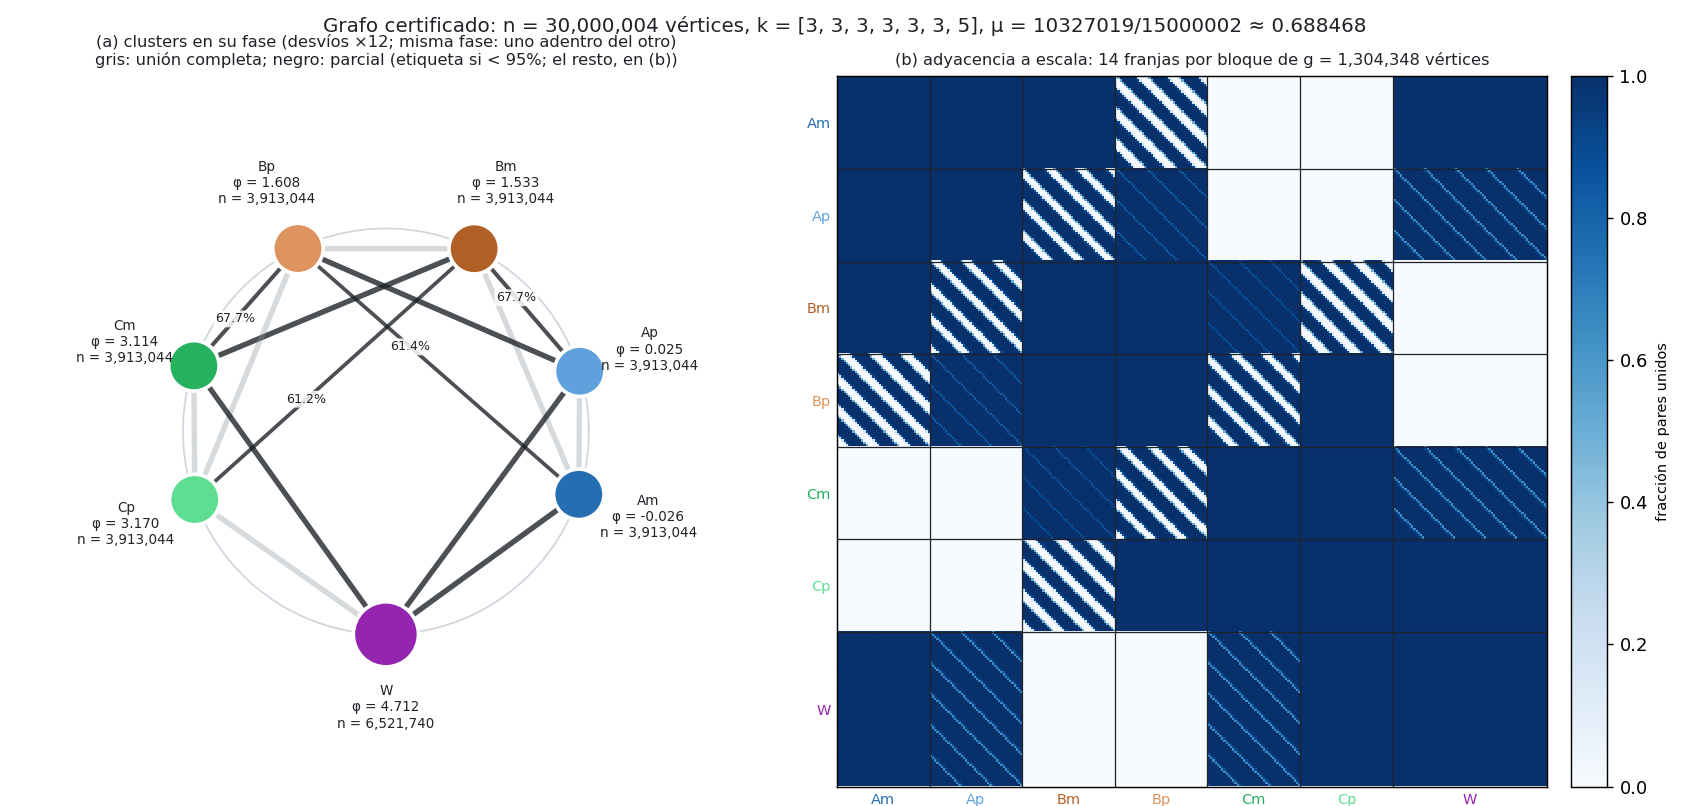

In [20]:
display(Image(filename="../data/figuras/grafo_n30000004_estructura.png"))

- **(a)** Es el "cuadrado" de C4: A en 0, B en $\pi/2$, C en $\pi$ y W en $3\pi/2$, con A, B y C partidos
  en dos mitades. Los clusters opuestos (A–C, B–W) no tienen aristas. Las únicas densidades lejos de
  0 y 1 son los cuatro pares cruzados entre mitades (61% y 68%): son las densidades $q$ del patrón
  límite de S7 (sección 3), abiertas por el SDP.
- **(b)** Los bloques llenos son los cliques y los pares completos; los blancos, los pares opuestos; y
  las **bandas diagonales** son los intervalos circulantes de la sección 7: con $t/g \approx 0.61$, cada
  vértice ve una ventana de vértices consecutivos que se corre con él.

## 8. Fase 3: el certificado

Hay que probar, sin errores de redondeo, que el grafo de $3\cdot 10^7$ vértices tiene un equilibrio no
sincronizado cuyo Hessiano es $\succ 0$ en $\mathbf 1^\perp$. El Hessiano tiene $(3\cdot 10^7)^2$
entradas, pero tiene mucha simetría.

### 8.1 Descomposición de Fourier

Correr $v \to v + 1$ en todos los bloques a la vez es un automorfismo del grafo (los cliques y los
intervalos se preservan) y no cambia las fases, que son constantes por cluster. Entonces $H$ conmuta
con ese corrimiento, y se diagonaliza en bloques con vectores
$\theta_{(a,i,v)} = z_{a,i}\, e^{2\pi \mathrm i m v/g}$, uno por frecuencia $m = 0, \dots, g - 1$.
Para cada $m$ queda una matriz hermítica $H_m$ de $K \times K$ ($K = \sum k_a = 23$):
$$H_m[(a,i),(b,j)] = \delta_{(a,i),(b,j)}\, D_a - \cos(\varphi_a - \varphi_b)\, \hat N_{ij}(m), \qquad
D_a = \sum_b d_{ab}\cos(\varphi_a - \varphi_b),$$
donde $\hat N_{ij}(m)$ es la transformada del conjunto de desplazamientos:
- entre clusters, $\hat N_{ij}(m) = \sum_{s < t_{ij}} e^{2\pi\mathrm i ms/g}$;
- dentro de un mismo bloque, $\hat N(m) = g[m{=}0] - 1$ (es $\mathbb Z_g \setminus \{0\}$);
- entre dos bloques distintos del mismo cluster, $\hat N(m) = g[m{=}0]$ (es $\mathbb Z_g$ completo).

El espectro de $H$ es la unión de los espectros de los $H_m$.

**El código** (copiado de `src/blowup.py`): la transformada de un intervalo, el Hessiano denso (para
comparar) y el bloque $H_m$.

In [21]:
def transformada_intervalo(t, g, m):
    # N̂(m) = Σ_{s=0}^{t−1} e^{2πi m s/g}.
    s = np.arange(t)
    return np.exp(2j * np.pi * m * s / g).sum()


def hessiano_denso(W, theta):
    # H = diag(Σ_v W_uv cos(θ_u − θ_v)) − [W_uv cos(θ_u − θ_v)].
    A = W * np.cos(theta[:, None] - theta[None, :])
    return np.diag(A.sum(axis=1)) - A


def hessiano_fourier(k, g, d, fases, m):
    # Bloque H_m (K × K, hermítico) del Hessiano del blow-up.
    K = sum(k)
    fases = np.asarray(fases, dtype=float)
    cos = np.cos(fases[:, None] - fases[None, :])
    inicio_bloque = np.cumsum([0] + list(k[:-1]))
    H = np.zeros((K, K), dtype=complex)
    for a in range(len(k)):
        diagonal = sum(d[a][b] * cos[a, b] for b in range(len(k)))
        for i in range(k[a]):
            fila = inicio_bloque[a] + i
            H[fila, fila] = diagonal - ((g if m == 0 else 0) - 1)
            for j in range(k[a]):
                if j != i:
                    H[fila, inicio_bloque[a] + j] = -(g if m == 0 else 0)
    for (a, b), t in tablas_bloques(k, g, d).items():
        for i in range(k[a]):
            for j in range(k[b]):
                valor = -cos[a, b] * transformada_intervalo(t[i][j], g, m)
                H[inicio_bloque[a] + i, inicio_bloque[b] + j] = valor
                H[inicio_bloque[b] + j, inicio_bloque[a] + i] = np.conj(valor)
    return H

Lo verificamos en el ejemplo chico de la sección 7 (con fases cualesquiera): los 30 autovalores del
Hessiano denso contra la unión de los espectros de los 5 bloques $H_m$ de $6 \times 6$.

In [22]:
fases_ejemplo = np.array([0.0, 0.4, -0.7])
theta_ejemplo = np.repeat(fases_ejemplo, tamanos_enteros(k_ejemplo, g_ejemplo))
denso = np.sort(np.linalg.eigvalsh(hessiano_denso(W_ejemplo, theta_ejemplo)))
por_bloques = []
for m in range(g_ejemplo):
    por_bloques.extend(np.linalg.eigvalsh(hessiano_fourier(k_ejemplo, g_ejemplo, d_ejemplo, fases_ejemplo, m)))
print("máxima diferencia entre espectros:", np.abs(denso - np.sort(por_bloques)).max())

máxima diferencia entre espectros: 1.4210854715202004e-14


### 8.2 Modos de cluster: el cociente de 7 × 7

Los vectores constantes en cada cluster, $\theta = \sum_a y_a \mathbf 1_a$, viven en $H_0$. Como cada
vértice de $a$ tiene exactamente $d_{ab}$ vecinos en $b$, $\mathbf 1_a^\top H \mathbf 1_b = -n_a d_{ab}
\cos(\varphi_a - \varphi_b)$, y entonces
$$\theta^\top H \theta = n^2 L(y)$$
con la plantilla entera $x_a = n_a/n$, $P_{ab} = d_{ab}/n_b$. El certificado de estos modos es un
certificado de la plantilla en **aritmética de intervalos** (`mpmath.iv`, 100 dígitos): cada número es
un intervalo que contiene al valor verdadero, y cada operación redondea hacia afuera. Una desigualdad
que vale para el intervalo entero es una prueba.

`src/certificado.py: certificar` hace cuatro pasos. Es largo (Krawczyk y Cholesky por intervalos, con
funciones auxiliares), así que va en pseudocódigo:

```text
certificar(x, P exactos (Fraction), φ̃ numérica):
    x, P ← intervalos de ancho 0 alrededor de las fracciones
    X ← caja de fases: φ_0 fijo, φ_a ∈ [φ̃_a − 1e-40, φ̃_a + 1e-40]

    1. Krawczyk (existencia y unicidad del equilibrio en X):
         Y ← inversa (en float) del Jacobiano J(φ̃)
         K ← φ̃ − Y F(φ̃) + (I − Y J(X)) (X − φ̃)          # todo con intervalos
         krawczyk ← K está en el interior de X

    2. c > 0: cota inferior de cada c_a = splitting(x, X, P, lib = iv)

    3. Cholesky por intervalos de L(x, X, P) sin la fila y columna 0 (eso saca la rotación):
         para cada pivote: si su cota inferior es ≤ 0, falla
         (si todos los pivotes son > 0, toda matriz simétrica del intervalo es definida positiva,
          en particular la de la solución verdadera)

    4. no sincronizado: alguna cota inferior de |sin((φ_a − φ_b)/2)| es > 0

    ok ← los cuatro pasos;  devolver ok, la caja X y el menor pivote
```

El paso 1 usa el teorema de Krawczyk: si $K(X) \subset \operatorname{int} X$, entonces hay una única
solución de $F = 0$ en $X$.

### 8.3 El resto de los modos: Gershgorin por bloques

Los demás modos son los $H_m$ con $m \ne 0$, más la parte de $H_0$ con $\sum_i z_{a,i} = 0$ en cada
cluster. En esos modos, la parte de cada cluster es diagonal: $(D_a + 1) I$. Los bloques entre
clusters son $-\cos_{ab}\, \hat N(m)$.

**Cota de Schur:** $\|\hat N\|_2 \le \sqrt{(\text{máx. suma de fila})(\text{máx. suma de columna})}$
de $|\hat N|$.
- **Para $m \ne 0$:** $|\hat N_{ij}(m)| \le \min(t_{ij}, g - t_{ij})$, porque la suma sobre todo
  $\mathbb Z_g$ es 0. Las sumas de fila quedan $\le \min(d_{ab}, n_b - d_{ab})$.
- **Para $m = 0$ con suma cero:** la parte constante $\text{base}\cdot J$ de la tabla se anula y solo
  actúan los "+1", con filas $\le d_{ab} - k_b\,\text{base}$.

En ninguno de los dos casos importa **qué** desplazamientos se eligieron, solo los grados.

**Gershgorin por bloques:** todo autovalor de esos modos es al menos
$$\min_a \Big( D_a + 1 - \sum_{b \ne a} |\cos_{ab}|\, \sqrt{s_{ab}} \Big),$$
con $s_{ab}$ el producto de las dos cotas de Schur. Con `lib = mpmath.iv` y los cosenos evaluados sobre
la caja de Krawczyk, la cota es rigurosa.

### 8.4 $\mu$ exacto

$\mu = (\delta + 1)/n$ se calcula con fracciones (`mu_entero`) y se compara con $11/16$ en aritmética
exacta.

**El código** (copiado de `src/blowup.py`): las cotas de Schur, los márgenes de Gershgorin y
`certificar_blowup`, que junta todo. `fases_newton` (Newton en alta precisión para $F = 0$) y
`certificar` se importan de `src/certificado.py`.

In [23]:
UMBRAL = Fraction(11, 16)


def acoplamientos(k, g, d):
    # Cotas de Schur s_ab de los acoplamientos entre clusters: (m ≠ 0, m = 0 con suma cero).
    m = len(k)
    n_a = tamanos_enteros(k, g)
    s_fourier = [[0] * m for _ in range(m)]
    s_cero = [[0] * m for _ in range(m)]
    for a in range(m):
        for b in range(a + 1, m):
            fila = min(d[a][b], n_a[b] - d[a][b])
            columna = min(d[b][a], n_a[a] - d[b][a])
            s_fourier[a][b] = s_fourier[b][a] = fila * columna
            base = (k[a] * d[a][b]) // (k[a] * k[b])
            fila = d[a][b] - k[b] * base
            columna = d[b][a] - k[a] * base
            s_cero[a][b] = s_cero[b][a] = fila * columna
    return s_fourier, s_cero


def margenes_gershgorin(k, g, d, fases, lib=np):
    # Margen por cluster: Σ_b d_ab cos_ab + 1 − Σ_{b≠a} |cos_ab| √s_ab, para cada tipo de modo.
    m = len(k)
    s_fourier, s_cero = acoplamientos(k, g, d)
    margenes = {"fourier": [], "cero": []}
    for a in range(m):
        cos = [lib.cos(fases[a] - fases[b]) for b in range(m)]
        diagonal = 1
        for b in range(m):
            diagonal = diagonal + d[a][b] * cos[b]
        for nombre, s in (("fourier", s_fourier), ("cero", s_cero)):
            total = diagonal
            for b in range(m):
                if b != a:
                    total = total - abs(cos[b]) * lib.sqrt(s[a][b])
            margenes[nombre].append(total)
    return margenes


def certificar_blowup(k, g, d, fases, dps=100, radio="1e-40"):
    # Certificado riguroso del blow-up: cociente (certificar) + Gershgorin sobre la caja + μ > 11/16.
    x, P = plantilla_entera(k, g, d)
    try:
        phi = fases_newton(x, P, fases, dps=dps + 20)
    except ZeroDivisionError:
        return {"ok": False, "motivo": "Newton no converge"}
    cociente = certificar(x, P, phi, radio=radio, dps=dps, verbose=False)
    margenes = margenes_gershgorin(k, g, d, cociente["caja"], lib=iv)
    menor_fourier = min(mp.mpf(v.a) for v in margenes["fourier"])
    menor_cero = min(mp.mpf(v.a) for v in margenes["cero"])
    mu = mu_entero(k, g, d)
    n = sum(k) * g
    ok = cociente["ok"] and menor_fourier > 0 and menor_cero > 0 and mu > UMBRAL
    return {
        "ok": bool(ok),
        "krawczyk": bool(cociente["krawczyk"]),
        "c>0": bool(cociente["c>0"]),
        "cholesky": bool(cociente["cholesky"]),
        "distintas": bool(cociente["distintas"]),
        "no sync": bool(cociente["no sync"]),
        "min pivote L (cota inf)": float(cociente["min pivote (cota inf)"]),
        "margen fourier / n (cota inf)": float(menor_fourier / n),
        "margen cero / n (cota inf)": float(menor_cero / n),
        "mu": float(mu), "mu_exacto": f"{mu.numerator}/{mu.denominator}",
        "mu > 11/16": bool(mu > UMBRAL),
        "radio caja": radio,
        "fases": [mp.nstr(p, 30) for p in phi],
    }

**El script de la Fase 3** (`scripts/certificar_grafo_s7.py`) certifica cada solución estricta de la
Fase 1 y guarda la descripción compacta del grafo junto con el resultado:

```text
para cada fila de data/s7_enteros.json con el reticulado estricto (de menor a mayor n):
    k ← (3, 3, 3, 3, 3, 3, 5)
    resultado ← certificar_blowup(k, g, d, fases)
    guardar descripción compacta (k, g, d, tablas, fases certificadas) + resultado
    con --control-negativo: también certificar_blowup del redondeo ingenuo del mismo n
                            (tiene que fallar)
```

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/certificar_grafo_s7.py</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU local (cualquiera)<br><b>Tiempo:</b> menos de 2 s en total<br><b>Salida:</b> <code>data/grafos_s7.json</code></td></tr>
<tr><td align="left"><pre>.venv/bin/python scripts/certificar_grafo_s7.py --control-negativo</pre></td></tr>
</table>

Es rápido, así que acá lo corremos en vivo para el grafo de $3\cdot 10^7$ vértices, junto con su
control negativo (el redondeo ingenuo del mismo $n$):

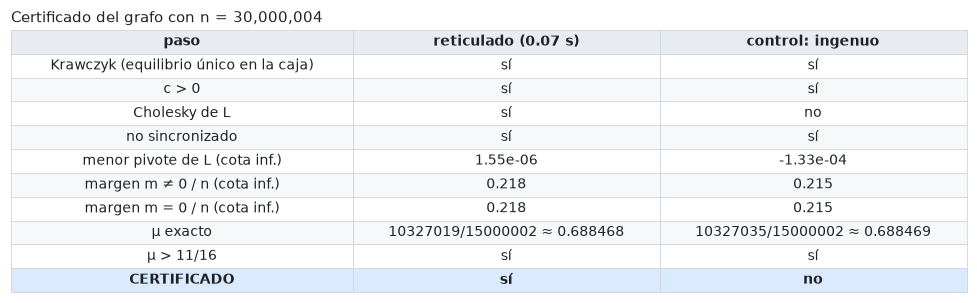

In [24]:
inicio = time.time()
resultado = certificar_blowup(descripcion["k"], descripcion["g"], descripcion["grados"], descripcion["fases"])
segundos = time.time() - inicio
assert resultado["ok"] == blowup.certificar_blowup(descripcion["k"], descripcion["g"], descripcion["grados"],
                                                   descripcion["fases"])["ok"]
d_control = grados_ingenuos(x_exacto, P_pulida, k_s7, descripcion["g"])
control = certificar_blowup(k_s7, descripcion["g"], d_control, [float(p) for p in phi_pulida])


def columna_certificado(r):
    # Valores de un resultado de certificar_blowup, en el orden de las filas de la tabla.
    return [si_no(r["krawczyk"]), si_no(r["c>0"]), si_no(r["cholesky"]), si_no(r["no sync"]),
            f"{r['min pivote L (cota inf)']:.2e}", f"{r['margen fourier / n (cota inf)']:.3f}",
            f"{r['margen cero / n (cota inf)']:.3f}", f"{r['mu_exacto']} ≈ {r['mu']:.6f}",
            si_no(r["mu > 11/16"]), si_no(r["ok"])]


etiquetas = ["Krawczyk (equilibrio único en la caja)", "c > 0", "Cholesky de L", "no sincronizado",
             "menor pivote de L (cota inf.)", "margen m ≠ 0 / n (cota inf.)", "margen m = 0 / n (cota inf.)",
             "μ exacto", "μ > 11/16", "CERTIFICADO"]
filas = []
for etiqueta, valor, valor_control in zip(etiquetas, columna_certificado(resultado), columna_certificado(control)):
    filas.append([etiqueta, valor, valor_control])
mostrar_tabla(["paso", f"reticulado ({segundos:.2f} s)", "control: ingenuo"], filas,
              titulo=f"Certificado del grafo con n = {descripcion['n']:,}", resaltar=[len(filas) - 1])

**Lectura.**
- **El grafo de $3 \cdot 10^7$ vértices queda certificado.**
- El menor pivote del Cholesky de $L$ es chico ($\sim 10^{-6}$), pero su cota inferior por intervalos
  es positiva. El resto de los modos tiene margen $\ge 0.217\,n$: el blow-up no cuesta nada, y toda la
  dificultad está en el cociente de $7 \times 7$.
- **En el control,** Krawczyk sí encuentra un equilibrio, pero el Cholesky falla: es el equilibrio
  inestable de la sección 5.

Todos los grafos de `data/grafos_s7.json`:

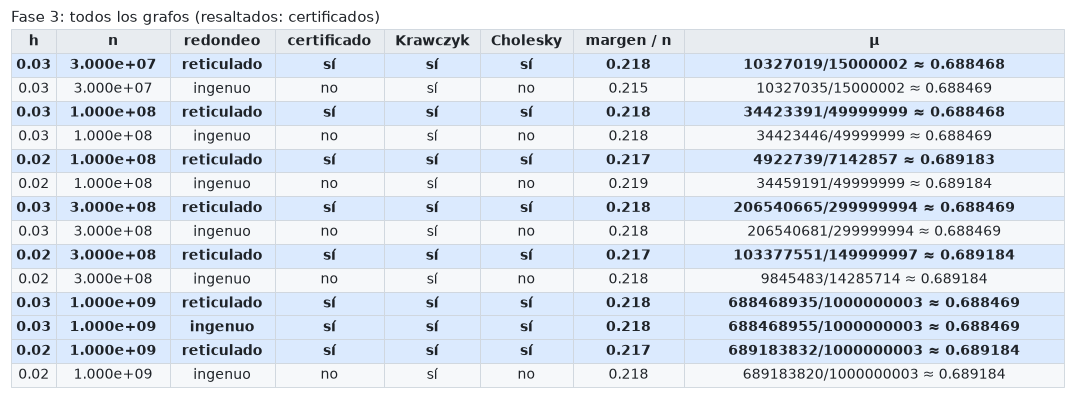

In [25]:
filas = []
resaltadas = []
for i, f in enumerate(grafos):
    c = f["certificado"]
    if "krawczyk" not in c:
        filas.append([f"{f['h']:.2f}", f"{f['grafo']['n']:.3e}", f["redondeo"], "no", "—", "—", "—", c["motivo"]])
        continue
    margen = min(c["margen fourier / n (cota inf)"], c["margen cero / n (cota inf)"])
    filas.append([f"{f['h']:.2f}", f"{f['grafo']['n']:.3e}", f["redondeo"], si_no(c["ok"]), si_no(c["krawczyk"]),
                  si_no(c["cholesky"]), f"{margen:.3f}", f"{c['mu_exacto']} ≈ {c['mu']:.6f}"])
    if c["ok"]:
        resaltadas.append(i)
mostrar_tabla(["h", "n", "redondeo", "certificado", "Krawczyk", "Cholesky", "margen / n", "μ"], filas,
              titulo="Fase 3: todos los grafos (resaltados: certificados)", resaltar=resaltadas)

- **Todos los grafos del reticulado quedan certificados.**
- **Los controles ingenuos fallan,** salvo $h = 0.03$ con $n = 10^9$, que ya era estricto en la Fase 1.

## 9. Fase 4: validación ciega

El certificado depende de que la teoría de las secciones 8.1–8.3 esté bien. Como chequeo independiente,
calculamos el espectro del Hessiano del grafo de $3\cdot 10^7$ vértices **directamente**: a partir de
la regla de adyacencia, sin Fourier ni Gershgorin, y en float64. Armar la matriz es imposible, porque
tiene $\sim 6\cdot 10^{14}$ entradas no nulas. Por eso solo usamos productos matriz-vector.

**$W y$ implícito:**
- **dentro de un cluster** (clique): $(Wy)_u = \sum_{v \in a} y_v - y_u$;
- **entre clusters:** el vértice $(a, i, v)$ recibe $\sum_j \sum_{s < t_{ij}} y_{(b,j,v+s)}$, una suma
  sobre una ventana cíclica, y $(b, j, w)$ recibe la ventana hacia atrás $\sum_i \sum_{s < t_{ij}} y_{(a,i,w-s)}$.

Con la suma prefija $S$ de $[y, y]$ (el bloque repetido dos veces, para no preocuparse por el
"mod $g$"), la ventana hacia adelante es $S[v + t] - S[v]$ y cada una cuesta $O(1)$. Un producto cuesta
$O(nk)$ y la memoria es $O(n)$.

**Dos detalles de implementación:**
- **Precisión:** cada bloque se centra por su media antes de la suma prefija (y la media se suma
  después, $t$ veces). Sin eso, las sumas prefijas de $10^6$ términos pierden dígitos.
- **Máscaras:** las tablas $t$ solo tienen dos valores distintos ($\text{base}$ y $\text{base}+1$).
  Para cada valor $t$ se guarda la matriz 0/1 $M_t$ de $k_a \times k_b$ con los pares $(i, j)$ que lo
  tienen. Las ventanas de todos los bloques de $b$ se calculan de una vez (una matriz $k_b \times g$), y
  $M_t$ las reparte entre los bloques de $a$: $M_t \cdot \text{ventanas}$.

**$H x$ implícito:**
$$Hx = h \circ x - \cos\theta \circ W(\cos\theta \circ x) - \sin\theta \circ W(\sin\theta \circ x),
\qquad h = \cos\theta \circ W\cos\theta + \sin\theta \circ W\sin\theta,$$
que sale de $\cos(\theta_u - \theta_v) = \cos\theta_u\cos\theta_v + \sin\theta_u\sin\theta_v$. Funciona
con cualquier vector de fases $\theta$, no usa que sean constantes por cluster.

**El código** (copiado de `src/validacion.py`). En `src/` son métodos de la clase `GrafoImplicito`,
que guarda $k$, $g$, las máscaras, $\cos\theta$, $\sin\theta$ y $h$, y que trabaja con numpy o con torch
(CPU o GPU) a través de un objeto `arreglos`. Acá están copiados como funciones que reciben ese
objeto como primer argumento (`grafo`); `grafo.por_cluster(y)` parte $y$ en una matriz $k_a \times g$
por cluster.

In [26]:
def producto_adyacencia(grafo, y):
    # W·y. Las ventanas cíclicas salen de sumas prefijas de y centrado por bloque (más preciso).
    g = grafo.g
    salida = grafo.arreglos.ceros(grafo.n)
    partes = grafo.por_cluster(y)
    partes_salida = grafo.por_cluster(salida)
    medias = []
    prefijas = []
    for a, Y in enumerate(partes):
        partes_salida[a] += Y.sum() - Y
        media = grafo.arreglos.media_filas(Y)
        medias.append(media)
        prefijas.append(grafo.arreglos.suma_prefija_doble(Y - media))
    for (a, b), mascaras in grafo.mascaras.items():
        for t, M in mascaras:
            # (a, i, v) recibe Σ_{s<t} y_(b, j, v+s);  (b, j, w) recibe Σ_{s<t} y_(a, i, w−s)
            adelante = prefijas[b][:, t: t + g] - prefijas[b][:, :g] + t * medias[b]
            atras = prefijas[a][:, g + 1: 2 * g + 1] - prefijas[a][:, g + 1 - t: 2 * g + 1 - t] + t * medias[a]
            partes_salida[a] += M @ adelante
            partes_salida[b] += M.T @ atras
    return salida


def producto_hessiano(grafo, x):
    # H·x con H = diag(Σ_v W_uv cos(θ_u − θ_v)) − [W_uv cos(θ_u − θ_v)].
    cruzado = (grafo.coseno * producto_adyacencia(grafo, grafo.coseno * x)
               + grafo.seno * producto_adyacencia(grafo, grafo.seno * x))
    return grafo.diagonal * x - cruzado

**Lanczos** encuentra el menor autovalor usando solo productos $Hx$. Genera una base ortonormal
$q_1, q_2, \dots$ del espacio de Krylov $\{x, Hx, H^2x, \dots\}$ con la recurrencia de tres términos
$$\beta_k q_{k+1} = Hq_k - \alpha_k q_k - \beta_{k-1}q_{k-1}.$$
- Los autovalores de la tridiagonal $T_k = \mathrm{tridiag}(\beta, \alpha, \beta)$ (los **valores de
  Ritz**) aproximan los extremos del espectro.
- Si $s$ es el autovector de $T_k$ del menor valor de Ritz $\vartheta$, el residuo de su vector de Ritz
  es $\|Hy - \vartheta y\| = \beta_k |s_k|$, y se calcula sin armar $y$.
- Solo hace falta guardar tres vectores ($3 \times 240$ MB para el grafo real).
- **Proyección:** para buscar el menor autovalor en un subespacio (por ejemplo $\mathbf 1^\perp$), se
  aplica la proyección después de cada producto.

**Detalle numérico.** El espectro del resto de los modos es muy degenerado (todos los $H_m$ se parecen),
y $\beta$ cae a $\sim 10^{-10}$ en pocos pasos. Entonces $w/\beta$ amplifica el redondeo en las
direcciones que se proyectaron afuera, donde el operador proyectado vale 0, y aparece un valor de Ritz
espurio $\approx 0$. Se evita reproyectando $w$ antes de normalizarlo.

**El código** (copiado de `src/validacion.py`):

In [27]:
def extremos_ritz(alfas, betas):
    # (menor valor de Ritz, último componente de su vector, mayor valor de Ritz) de la tridiagonal.
    if len(alfas) == 1:
        return alfas[0], 1.0, alfas[0]
    menor, vector = eigh_tridiagonal(alfas, betas[:-1], select="i", select_range=(0, 0))
    mayor = eigh_tridiagonal(alfas, betas[:-1], eigvals_only=True, select="i",
                             select_range=(len(alfas) - 1, len(alfas) - 1))
    return float(menor[0]), float(vector[-1, 0]), float(mayor[0])


def lanczos(aplicar, proyectar, inicial, arreglos, iteraciones, cada=25, tolerancia=1e-6):
    # Lanczos sin reortogonalizar para el menor autovalor de un operador simétrico, con proyección.
    q = proyectar(inicial)
    q = q / arreglos.norma(q)
    q_anterior = None
    beta = 0.0
    alfas = []
    betas = []
    historial = []
    escala = 0.0
    for paso in range(1, iteraciones + 1):
        w = proyectar(aplicar(q))
        alfa = arreglos.punto(q, w)
        w = w - alfa * q
        if q_anterior is not None:
            w = w - beta * q_anterior
        # reproyectar: si β es chico, w/β amplifica el redondeo en las direcciones proyectadas
        w = proyectar(w)
        beta = arreglos.norma(w)
        alfas.append(alfa)
        betas.append(beta)
        escala = max(escala, abs(alfa))
        final = paso == iteraciones or beta <= 1e-12 * escala
        if paso % cada == 0 or final:
            menor, ultimo, mayor = extremos_ritz(np.array(alfas), np.array(betas))
            historial.append({"paso": paso, "menor": menor, "residuo": beta * abs(ultimo), "mayor": mayor})
            if historial[-1]["residuo"] <= tolerancia * abs(menor) or final:
                break
        q_anterior = q
        q = w / beta
    return {"menor": historial[-1]["menor"], "residuo": historial[-1]["residuo"],
            "mayor": historial[-1]["mayor"], "pasos": historial[-1]["paso"], "historial": historial}

**Prueba en un análogo chico.** Mismas densidades y fases que el grafo real, pero $g = 60$
($n = 1380$), donde sí se puede armar el Hessiano denso. Comparamos:
1. el producto implícito $Hx$ contra el denso;
2. Lanczos contra `eigvalsh` del Hessiano denso restringido al subespacio, en los dos casos que usa la
   validación: el complemento de los modos de cluster (proyección: restar la media de cada cluster) y
   $\mathbf 1^\perp$ (restar la media global).

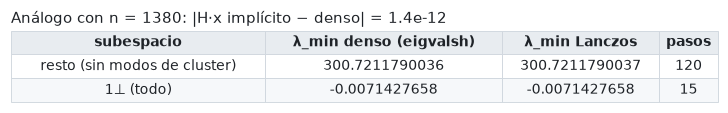

In [28]:
k_real = descripcion["k"]
g_analogo = 60
n_analogo = tamanos_enteros(k_real, g_analogo)
d_analogo = [[0] * 7 for _ in range(7)]
for a in range(7):
    d_analogo[a][a] = n_analogo[a] - 1
    for b in range(a + 1, 7):
        paso = paso_grado(k_real, a, b)
        d_analogo[a][b] = int(round(descripcion["grados"][a][b] / tamanos_reales[b] * n_analogo[b] / paso)) * paso
        d_analogo[b][a] = d_analogo[a][b] * n_analogo[a] // n_analogo[b]
fases_reales = [float(p) for p in descripcion["fases"]]
analogo = GrafoImplicito(blowup.descripcion_compacta(k_real, g_analogo, d_analogo, fases_reales), Arreglos())
theta_analogo = np.repeat(fases_reales, n_analogo)
H_analogo = hessiano_denso(adyacencia_densa(k_real, g_analogo, d_analogo), theta_analogo)

x_prueba = np.random.default_rng(1).standard_normal(analogo.n)
diferencia = np.abs(producto_hessiano(analogo, x_prueba) - H_analogo @ x_prueba).max()
assert np.allclose(producto_hessiano(analogo, x_prueba), analogo.producto_hessiano(x_prueba))


def complemento(base):
    # Base ortonormal del complemento de las columnas de base.
    Q, _ = np.linalg.qr(np.hstack([base, np.eye(base.shape[0])]))
    return Q[:, base.shape[1]:]


indicadoras = np.zeros((analogo.n, 7))
for a in range(7):
    indicadoras[analogo.inicios[a]: analogo.inicios[a] + n_analogo[a], a] = 1
casos = [("resto (sin modos de cluster)", analogo.quitar_medias_cluster, complemento(indicadoras)),
         ("1⊥ (todo)", analogo.quitar_media, complemento(np.ones((analogo.n, 1))))]
filas = []
for nombre, proyectar, C in casos:
    exacto = np.linalg.eigvalsh(C.T @ H_analogo @ C).min()
    r = lanczos(lambda v: producto_hessiano(analogo, v), proyectar, analogo.arreglos.aleatorio(analogo.n, 0),
                analogo.arreglos, iteraciones=2000, cada=5, tolerancia=1e-9)
    filas.append([nombre, f"{exacto:.10f}", f"{r['menor']:.10f}", r["pasos"]])
mostrar_tabla(["subespacio", "λ_min denso (eigvalsh)", "λ_min Lanczos", "pasos"], filas,
              titulo=f"Análogo con n = {analogo.n}: |H·x implícito − denso| = {diferencia:.1e}")

Coinciden. Además, el análogo con $n = 1380$ es **inestable** ($\lambda_{\min} < 0$ en $\mathbf 1^\perp$):
con las mismas densidades redondeadas a un $n$ chico, el equilibrio no sobrevive. Es otra vez el
pliegue de la sección 5.

**El script de la Fase 4** (`scripts/validar_grafo.py`) corre cinco chequeos sobre el grafo real:

```text
grafo ← GrafoImplicito(descripción compacta de data/grafos_s7.json, numpy o torch en cpu/cuda)
1. grados:     W·1_b cuenta los vecinos de cada vértice en cada cluster b
               → mínimo y máximo por cluster tienen que ser exactamente d_ab (enteros: exacto en float64)
2. velocidad:  θ̇ = cos θ ∘ W sin θ − sin θ ∘ W cos θ   →  max |θ̇|  (tiene que ser error de redondeo)
3. modos de cluster:  Q_ab = 1_aᵀ H 1_b / √(n_a n_b) con H·x implícito
               → comparar con la fórmula de los grados; autovalores de Q (uno es la rotación ≈ 0)
4. resto:      Lanczos con proyección = restar la media de cada cluster
               → λ_min, comparado con la cota de Gershgorin del certificado
5. (--completo) Lanczos ciego en 1^⊥ desde un vector al azar → tiene que dar el menor autovalor de Q
guardar todo en data/validacion_s7_n<n>.json
```

Como el subespacio de los modos de cluster es invariante (por el chequeo 1), los pasos 3 y 4 ya dan
$\lambda_{\min}(H|_{\mathbf 1^\perp})$. El paso 5 lo confirma sin suponer nada.

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/validar_grafo.py</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> server con GPU (GTX 1080 Ti, torch + CUDA); también corre en CPU sin torch<br><b>Tiempo:</b> GPU: 0.73 s por producto H·x, 83 s en total · CPU: 4.5 s por producto, varios minutos<br><b>Salida:</b> <code>data/validacion_s7_n30000004.json</code></td></tr>
<tr><td align="left"><pre># server (GPU): los cinco chequeos, con el log en un archivo
nohup python scripts/validar_grafo.py --dispositivo cuda --completo &gt; validacion_n3e7.log 2&gt;&amp;1 &amp;

<tr><td align="left"><pre># CPU sin torch: chequeos 1–4
.venv/bin/python scripts/validar_grafo.py --dispositivo numpy --iteraciones 200 --cada 10</pre></td></tr>
</table>

La GPU sirve porque cada producto recorre vectores de 240 MB con sumas prefijas: es un cálculo
limitado por memoria, y la 1080 Ti rinde bien aun en float64. Resultados de la corrida en el server:

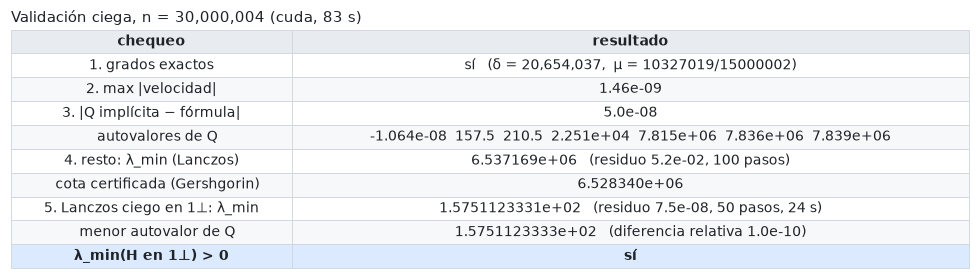

In [29]:
v = cargar_json("validacion_s7_n30000004.json")
c = v["completo"]
diferencia_relativa = abs(c["menor"] - v["menor_cluster"]) / v["menor_cluster"]
autovalores_Q = "  ".join(f"{a:.4g}" for a in v["autovalores_Q"])
mostrar_tabla(["chequeo", "resultado"], [
    ["1. grados exactos", f"{si_no(v['grados_ok'])}   (δ = {v['grado_min']:,},  μ = {v['mu_exacto']})"],
    ["2. max |velocidad|", f"{v['max_velocidad']:.2e}"],
    ["3. |Q implícita − fórmula|", f"{v['Q_diferencia']:.1e}"],
    ["   autovalores de Q", autovalores_Q],
    ["4. resto: λ_min (Lanczos)", f"{v['resto']['menor']:.6e}   (residuo {v['resto']['residuo']:.1e}, {v['resto']['pasos']} pasos)"],
    ["   cota certificada (Gershgorin)", f"{v['cota_gershgorin']:.6e}"],
    ["5. Lanczos ciego en 1⊥: λ_min", f"{c['menor']:.10e}   (residuo {c['residuo']:.1e}, {c['pasos']} pasos, {c['segundos']:.0f} s)"],
    ["   menor autovalor de Q", f"{v['menor_cluster']:.10e}   (diferencia relativa {diferencia_relativa:.1e})"],
    ["λ_min(H en 1⊥) > 0", si_no(v["estable"])],
], titulo=f"Validación ciega, n = {v['n']:,} ({v['dispositivo']}, {v['segundos']:.0f} s)", resaltar=[8])

**Lectura.**
- **Grados:** exactos.
- **Velocidad:** $\sim 10^{-9}$, es decir error de redondeo para fuerzas de tamaño $\sim n$.
- **$Q$:** coincide con la fórmula. Sus autovalores son 0 (la rotación), luego **157.5** y 210.5 (los
  modos casi neutros de S7), y después $2.3\cdot10^4$ y tres $\approx 7.8\cdot 10^6$.
- **Resto:** $\lambda_{\min} = 6.537\cdot 10^6$, apenas arriba de la cota de Gershgorin
  $6.528\cdot 10^6$. La cota es casi justa.
- **Lanczos ciego en $\mathbf 1^\perp$:** desde un vector al azar, sin separar nada, llega a
  $\lambda_{\min} = 157.51123331$, con residuo $7.5\cdot 10^{-8}$. Coincide con el menor autovalor de $Q$
  con diferencia relativa $10^{-10}$.
  - Convergió en solo 50 pasos. El espectro de $H$ en $\mathbf 1^\perp$ son unos pocos autovalores
    aislados (157.5, 210.5, $2.3\cdot10^4$) y una banda lejana $[6.5\cdot10^6, 7.95\cdot10^6]$, y
    Lanczos atrapa cada autovalor aislado en pocos pasos.
  - Que el vector inicial casi no tenga peso en esos modos (son 6 direcciones entre $3\cdot 10^7$) solo
    agrega un factor logarítmico.

Dividido por $n$, $157.5/n \approx 5.25\cdot 10^{-6}$: es el mismo menor autovalor normalizado de $L$
que dio la Fase 1 (columna λ_min(L) de la tabla de la sección 6).

**Conclusión de la Fase 4:** el Hessiano del grafo de $3\cdot 10^7$ vértices, calculado de manera ciega
en float64, es definido positivo en $\mathbf 1^\perp$ con $\lambda_{\min} = 157.5$, como dice el
certificado.

## 10. La dinámica: simular Kuramoto sobre el grafo

El certificado prueba que el estado $\theta^*$ es un **mínimo local estricto**: toda perturbación
suficientemente chica vuelve. No dice **cuán chica**. Acá simulamos la dinámica para verlo, en tiempo
normalizado:
$$\dot\theta_u = \frac1n \sum_v W_{uv}\sin(\theta_v - \theta_u).$$

**Escalas de tiempo.** Linealizando en $\theta^*$, $\dot{\delta\theta} = -(H/n)\,\delta\theta$, así que
cada modo decae a tasa $\lambda/n$. Por la sección 9:
- los modos **dentro de los clusters** (el "resto") tienen $\lambda/n \ge 0.218$: se apagan en $t \sim 10$–$50$;
- los **modos de cluster** tienen tasas $157.5/n \approx 5.3\cdot10^{-6}$, $210.5/n \approx 7.0\cdot10^{-6}$,
  $7.5\cdot10^{-4}$ y $\approx 0.26$: los dos primeros tardan $t \sim 10^5$–$10^6$.

Una simulación del grafo completo hasta $t \sim 10^6$ sería imposible (cada paso son varios productos
$W\cdot y$ de $3\cdot10^7$ entradas). Pero no hace falta:

**Reducción exacta a los clusters.** Si todos los vértices de cada cluster tienen la misma fase $y_a$,
como cada vértice de $a$ tiene **exactamente** $d_{ab}$ vecinos en $b$,
$$\dot y_a = \sum_b \frac{d_{ab}}{n}\sin(y_b - y_a),$$
y el estado sigue siendo constante por cluster. Es una ecuación por cluster, **exacta** para el grafo
(no una aproximación de campo medio), y se integra hasta $t = 10^7$ en milisegundos con un integrador
para sistemas rígidos (LSODA). Su Jacobiano en $\varphi$ tiene autovalores $-\lambda/n$ de los modos de
cluster.

**Por qué esperamos una cuenca chica.** En las dos direcciones lentas la fuerza de retorno es
$\sim 5\cdot10^{-6}\,y$, mientras que los términos no lineales son $\sim c\,y^2$ con $c$ de orden 1. Se
compensan en $y \sim 10^{-5}$–$10^{-4}$: más lejos que eso, la dinámica ya no vuelve. Es el mismo
pliegue de la sección 5, ahora visto como tamaño de la cuenca.

**El código** (copiado de `scripts/visualizar_grafo.py`): el campo por clusters con su Jacobiano y la
integración, que mide la distancia a $\varphi$ sin la rotación global y $r = |\sum_a x_a e^{\mathrm i y_a}|$.

In [30]:
def campo_clusters(descripcion):
    # (f, jac) de ẏ_a = Σ_b (d_ab/n) sin(y_b − y_a): Kuramoto normalizado restringido a estados constantes por cluster.
    A = np.array(descripcion["grados"], dtype=float) / descripcion["n"]

    def f(t, y):
        return (A * np.sin(y[None, :] - y[:, None])).sum(axis=1)

    def jac(t, y):
        C = A * np.cos(y[None, :] - y[:, None])
        np.fill_diagonal(C, 0)
        return C - np.diag(C.sum(axis=1))

    return f, jac


def envolver(angulo):
    # Ángulo llevado a [−π, π).
    return (angulo + np.pi) % (2 * np.pi) - np.pi


def integrar_clusters(descripcion, y0, tiempo, puntos=120):
    # Integra la dinámica por clusters desde y0 (LSODA): tiempos, distancia a las fases certificadas y r.
    fases = np.array([float(p) for p in descripcion["fases"]])
    x = np.array(descripcion["k"], dtype=float) / sum(descripcion["k"])
    f, jac = campo_clusters(descripcion)
    tiempos = np.concatenate([[0], np.logspace(-1, np.log10(tiempo), puntos)])
    sol = solve_ivp(f, (0, tiempo), y0, method="LSODA", jac=jac, rtol=1e-10, atol=1e-13, t_eval=tiempos)
    distancias = []
    radios = []
    for y in sol.y.T:
        diferencia = envolver(y - fases)
        distancias.append(float(np.abs(envolver(diferencia - np.sum(x * diferencia))).max()))
        radios.append(float(abs(np.sum(x * np.exp(1j * y)))))
    return sol.t, distancias, radios

**Corrida en vivo** sobre el grafo de $3\cdot10^7$ vértices: primero las tasas (autovalores del
Jacobiano, contra los de la validación), y después perturbaciones de tamaño $\delta$ en la dirección
más lenta y en una dirección al azar (sin componente de rotación), integradas hasta $t = 10^7$.

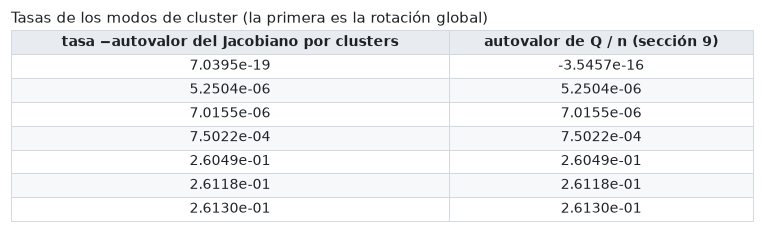

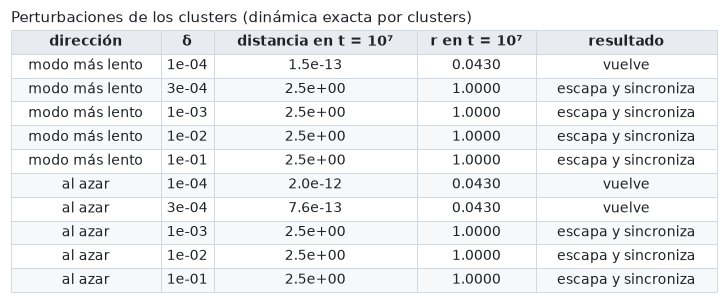

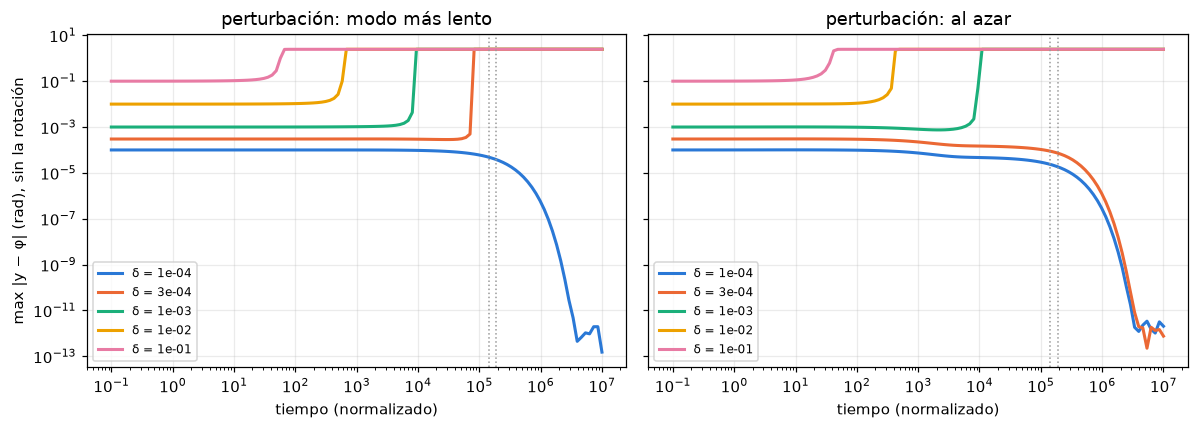

In [31]:
fases_cluster = np.array([float(p) for p in descripcion["fases"]])
x_cluster = np.array(descripcion["k"], dtype=float) / sum(descripcion["k"])
_, jac_cluster = campo_clusters(descripcion)
autovalores, vectores = np.linalg.eig(jac_cluster(0, fases_cluster))
orden = np.argsort(-autovalores.real)
tasas = -autovalores.real[orden]
v = cargar_json("validacion_s7_n30000004.json")
filas = []
for tasa, lam in zip(tasas, sorted(v["autovalores_Q"])):
    filas.append([f"{tasa:.4e}", f"{lam / v['n']:.4e}"])
mostrar_tabla(["tasa −autovalor del Jacobiano por clusters", "autovalor de Q / n (sección 9)"], filas,
              titulo="Tasas de los modos de cluster (la primera es la rotación global)")

direcciones = {"modo más lento": vectores[:, orden[1]].real,
               "al azar": np.random.default_rng(0).standard_normal(7)}
amplitudes = [1e-4, 3e-4, 1e-3, 1e-2, 1e-1]
corridas = {}
filas = []
for nombre, direccion in direcciones.items():
    direccion = direccion - np.sum(x_cluster * direccion)
    direccion = direccion / np.abs(direccion).max()
    for delta in amplitudes:
        tiempos, distancias, radios = integrar_clusters(descripcion, fases_cluster + delta * direccion, 1e7)
        corridas[(nombre, delta)] = (tiempos, distancias)
        vuelve = distancias[-1] < 1e-6
        filas.append([nombre, f"{delta:.0e}", f"{distancias[-1]:.1e}", f"{radios[-1]:.4f}",
                      "vuelve" if vuelve else "escapa y sincroniza"])
mostrar_tabla(["dirección", "δ", "distancia en t = 10⁷", "r en t = 10⁷", "resultado"], filas,
              titulo="Perturbaciones de los clusters (dinámica exacta por clusters)")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, nombre in zip(ejes, direcciones):
    for color, delta in zip(COLORES, amplitudes):
        tiempos, distancias = corridas[(nombre, delta)]
        eje.plot(tiempos[1:], distancias[1:], color=color, lw=2, label=f"δ = {delta:.0e}")
    for tasa in tasas[1:3]:
        eje.axvline(1 / tasa, color="0.6", lw=1, ls=":")
    eje.set(xscale="log", yscale="log", xlabel="tiempo (normalizado)", title=f"perturbación: {nombre}")
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)
ejes[0].set_ylabel("max |y − φ| (rad), sin la rotación")
plt.tight_layout()
plt.show()

- **Las tasas coinciden** con los autovalores de $Q$ de la validación ciega divididos por $n$: la
  reducción a clusters es la misma dinámica.
- **$\delta = 10^{-4}$ vuelve** en las dos direcciones, en la escala $1/\lambda \sim 2\cdot10^5$ (líneas
  punteadas), hasta distancias de $10^{-12}$.
- **$\delta \ge 3\cdot 10^{-4}$ en la dirección lenta escapa**: la distancia se queda casi quieta un rato
  largo (la fuerza es diminuta) y después salta a $\approx 2.46$ con $r = 1$: **sincroniza**. En la
  dirección al azar el borde está entre $3\cdot10^{-4}$ y $10^{-3}$ (esa dirección tiene parte en modos
  rápidos, que vuelven solos).

La cuenca de la trampa, en las direcciones lentas, mide entre $10^{-4}$ y $3\cdot10^{-4}$ radianes.

### 10.1 El grafo completo

**Qué hace el script.** `scripts/visualizar_grafo.py --simular perturbado,azar` integra la dinámica
del grafo completo con los productos implícitos de la sección 9 y, cuando los clusters ya están
concentrados, sigue con la dinámica exacta por clusters:

```text
θ̇(θ) = (cos θ ∘ W sin θ − sin θ ∘ W cos θ) / n          # W·y implícito: dos productos por evaluación
paso RK4 con dt = 0.5:  k1 = θ̇(θ), k2 = θ̇(θ + dt/2 k1), k3 = θ̇(θ + dt/2 k2), k4 = θ̇(θ + dt k3)
                        θ ← θ + dt/6 (k1 + 2 k2 + 2 k3 + k4)

inicial "perturbado":  θ* + ruido gaussiano de desvío σ, al que se le resta la media en cada cluster
                       (solo se perturban los modos internos: los clusters enteros arrancan en su lugar)
inicial "azar":        fases uniformes en [0, 2π)

hasta t = 60: guardar r = |⟨e^{iθ}⟩| y max|θ − θ* − giro| en cada paso, y fotos de 4000 vértices
después: y0 ← fase media circular de cada cluster (desenvuelta respecto de φ)
         integrar_clusters(y0) hasta t = 10⁷
```

La continuación es válida porque al final de la simulación completa los modos internos ya decayeron
($e^{-0.22\cdot 60} \sim 10^{-6}$): el estado es constante por cluster salvo errores de ese orden.

<table>
<tr><th align="left">▶ Cómo correr <code>scripts/visualizar_grafo.py --simular</code> (desde la raíz del repo)</th></tr>
<tr><td align="left"><b>Máquina:</b> server con GPU (GTX 1080 Ti, torch + CUDA) para n = 3·10⁷; el grafo B (n = 1.5·10⁶) corre en CPU local<br><b>Tiempo:</b> GPU: ~6 min por simulación del grafo completo · CPU con el grafo B: ~2.5 min<br><b>Salida:</b> <code>data/figuras/grafo_n<n>_sim_*.png y data/simulacion_n<n>.json (una clave por corrida)</code></td></tr>
<tr><td align="left"><pre># server (GPU): las tres simulaciones con ruido 0.05, y después ruido 0.5
nohup sh -c &quot;python scripts/visualizar_grafo.py --n 30000004 --simular perturbado,azar,clusters --ruido 0.05 --dispositivo cuda &amp;&amp; python scripts/visualizar_grafo.py --n 30000004 --simular perturbado --ruido 0.5 --dispositivo cuda&quot; &gt; simulacion_n3e7.log 2&gt;&amp;1 &amp;

# local (CPU), grafo B
.venv/bin/python scripts/visualizar_grafo.py --simular perturbado,azar,clusters --ruido 0.05</pre></td></tr>
</table>

**Resultados** de la corrida en el server para el grafo de $3\cdot10^7$ vértices
(`data/simulacion_n30000004.json`):

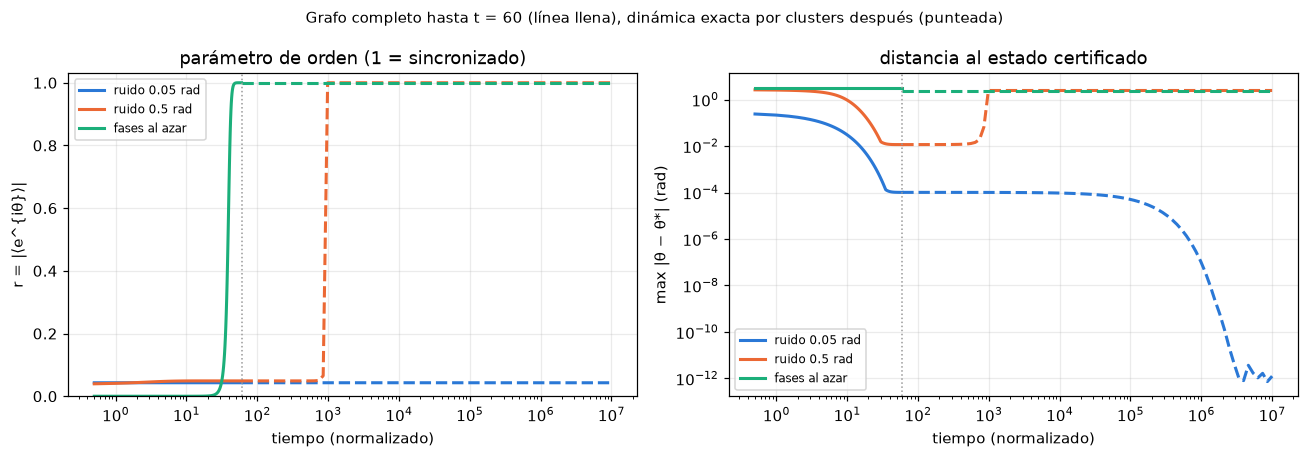

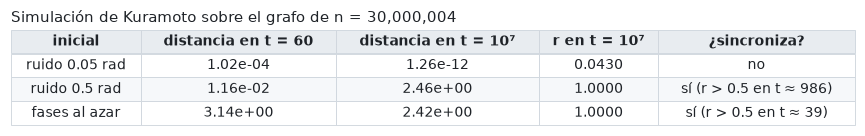

In [32]:
simulacion = cargar_json("simulacion_n30000004.json")
corridas_completas = [("perturbado_ruido0.05", "ruido 0.05 rad", COLORES[0]),
                      ("perturbado_ruido0.5", "ruido 0.5 rad", COLORES[1]),
                      ("azar", "fases al azar", COLORES[2])]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
filas = []
for clave, etiqueta, color in corridas_completas:
    completo = simulacion[clave]["grafo completo"]
    continuacion = simulacion[clave]["continuacion"]
    for eje, cantidad in zip(ejes, ["r", "distancia"]):
        eje.plot(completo["t"][1:], completo[cantidad][1:], color=color, lw=2, label=etiqueta)
        eje.plot(continuacion["t"], continuacion[cantidad], color=color, lw=2, ls="--")
    sincroniza = None
    for t, r in zip(completo["t"] + continuacion["t"], completo["r"] + continuacion["r"]):
        if r > 0.5:
            sincroniza = t
            break
    filas.append([etiqueta, f"{completo['distancia'][-1]:.2e}", f"{continuacion['distancia'][-1]:.2e}",
                  f"{continuacion['r'][-1]:.4f}", "no" if sincroniza is None else f"sí (r > 0.5 en t ≈ {sincroniza:.0f})"])
for eje in ejes:
    eje.axvline(60, color="0.6", lw=1, ls=":")
    eje.set(xscale="log", xlabel="tiempo (normalizado)")
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)
ejes[0].set(ylabel="r = |⟨e^{iθ}⟩|", ylim=(0, 1.03), title="parámetro de orden (1 = sincronizado)")
ejes[1].set(ylabel="max |θ − θ*| (rad)", yscale="log", title="distancia al estado certificado")
fig.suptitle("Grafo completo hasta t = 60 (línea llena), dinámica exacta por clusters después (punteada)",
             fontsize=10)
plt.tight_layout()
plt.show()

mostrar_tabla(["inicial", "distancia en t = 60", "distancia en t = 10⁷", "r en t = 10⁷", "¿sincroniza?"], filas,
              titulo=f"Simulación de Kuramoto sobre el grafo de n = {simulacion['n']:,}")

Las fotos de las fases de 4000 vértices al azar (colores por cluster) en $t = 0, 3, 15, 60$, con ruido
0.5 rad:

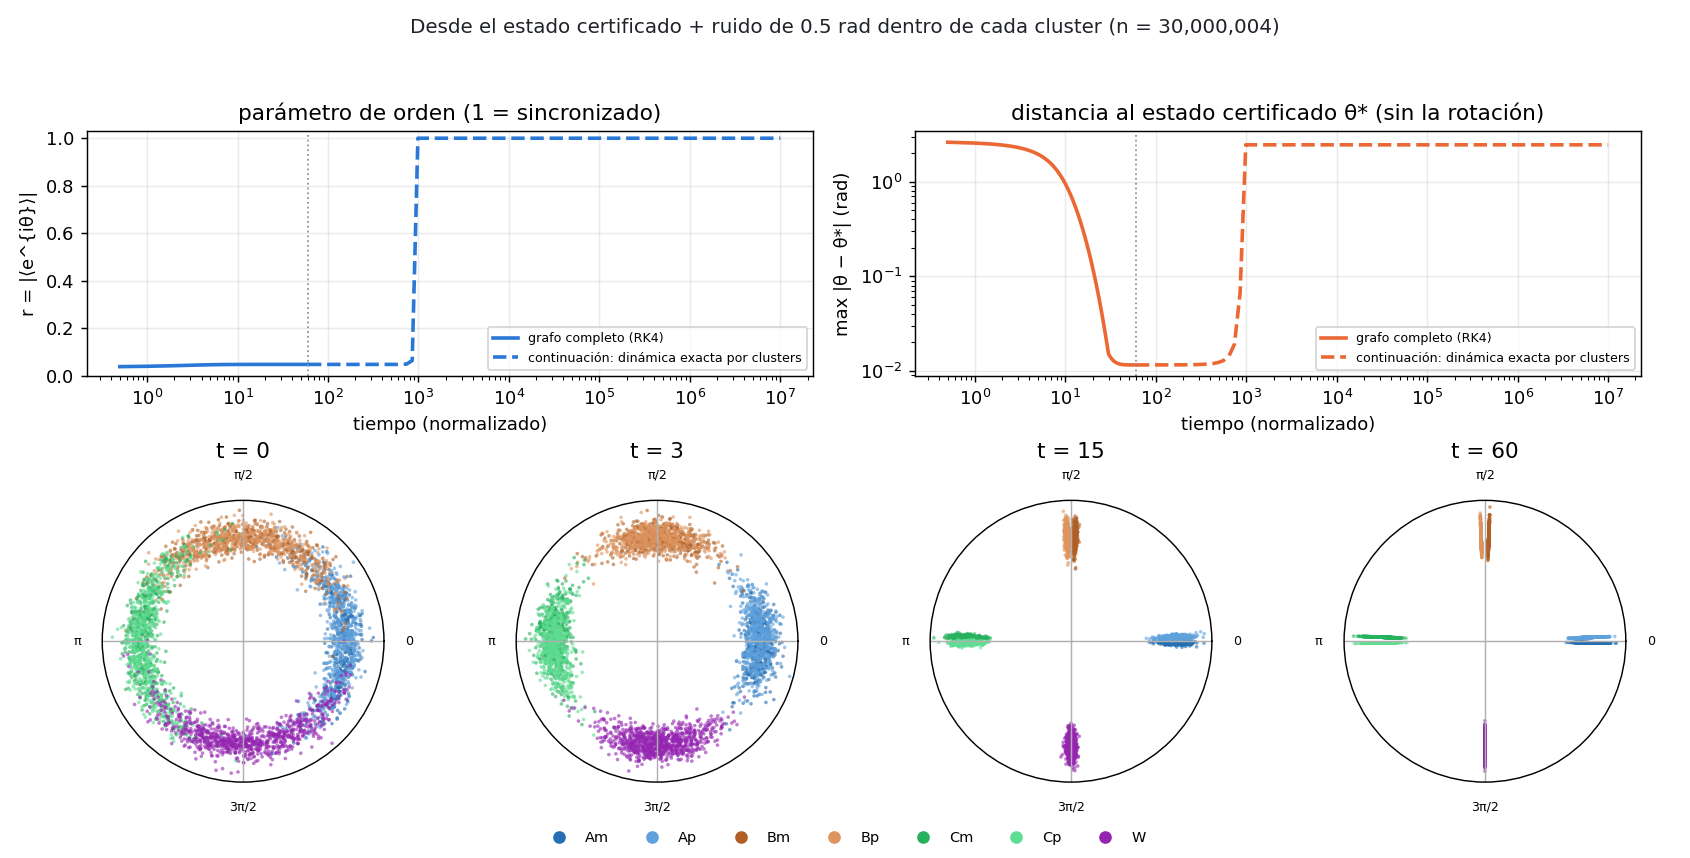

In [33]:
display(Image(filename="../data/figuras/grafo_n30000004_sim_perturbado_ruido0.5.png"))

**Lectura.**
- **Ruido 0.05 rad: vuelve.** Los modos internos se apagan en $t \approx 35$; queda un corrimiento de
  los clusters enteros de $10^{-4}$, que vuelve en la escala lenta ($t \sim 10^6$) hasta $10^{-12}$.
  El estado nunca deja de estar a la vista: $r$ queda en 0.043, el valor del estado certificado.
- **Ruido 0.5 rad: escapa.** Las fotos muestran los cuatro grupos formándose en $0, \pi/2, \pi,
  3\pi/2$ y el ruido apagándose, pero queda un corrimiento de los clusters de $1.2\cdot 10^{-2}$, fuera
  de la cuenca, y en $t \approx 1000$ el estado sincroniza.
- **De dónde sale el corrimiento**, si el ruido tiene media 0 en cada cluster: mientras los clusters
  están desparramados, cada uno tira con fuerza $\propto \langle\cos\rangle$ de su dispersión, y como se
  relajan a velocidades un poco distintas, las fuerzas netas no se cancelan del todo. Es un efecto de
  segundo orden: el corrimiento escala como $\sigma^2$ ($10^{-4}$ con 0.05, $10^{-2}$ con 0.5).
- **Fases al azar: sincroniza** (en $t \approx 40$; arranca con $r \sim n^{-1/2}$ y crece
  exponencialmente).

**Conclusión.** La trampa es real: la dinámica del grafo de $3\cdot10^7$ vértices vuelve al estado
certificado desde perturbaciones chicas. Pero su cuenca es **diminuta** en las direcciones lentas
($\sim 10^{-4}$ rad), una consecuencia directa de estar al lado del pliegue: el margen que se
resignó en la Fase 0 ($\varepsilon = 10^{-3}$) compra un grafo chico, no una trampa robusta. Para la
pregunta de $\mu_c$ alcanza con que el mínimo sea estricto (lo es); si se quisiera una trampa que se
vea en simulaciones "genéricas", habría que pagar más margen, y con eso, menos $\mu$.

## 11. Resumen y siguiente paso

- **Resultado:** un grafo explícito con $n = 30\,000\,004$ y $\mu = 10327019/15000002 \approx 0.688468 > 11/16$,
  con un equilibrio no sincronizado **certificado** como mínimo local estricto.
  - Está descrito por $k$, $g$, una matriz de grados de $7\times 7$ y las tablas de transporte
    (`data/grafos_s7.json`).
  - El certificado tarda menos de un segundo y la validación ciega en float64 coincide.
- **Por qué funciona:**
  1. tamaños racionales desde el principio;
  2. densidades óptimas con margen (SDP), en lugar de las perturbativas;
  3. redondeo por reticulado, que esquiva el pliegue;
  4. un blow-up circulante con grados exactos, en el que el resto de los modos tiene margen
     $\ge 0.2\,n$ sin importar los desplazamientos.
- **Dinámica:** la simulación confirma la trampa (desde cerca vuelve), pero su cuenca en las
  direcciones lentas es de $\sim 10^{-4}$ rad; desde fases al azar el grafo sincroniza.

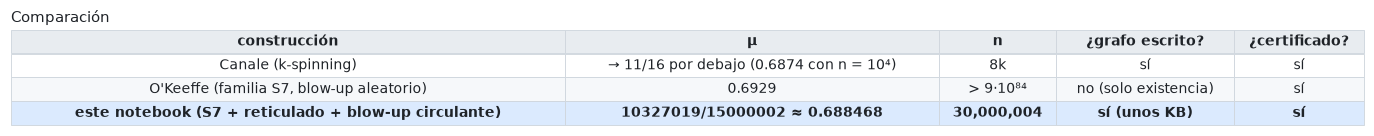

In [34]:
mostrar_tabla(["construcción", "μ", "n", "¿grafo escrito?", "¿certificado?"], [
    ["Canale (k-spinning)", "→ 11/16 por debajo (0.6874 con n = 10⁴)", "8k", "sí", "sí"],
    ["O'Keeffe (familia S7, blow-up aleatorio)", "0.6929", "> 9·10⁸⁴", "no (solo existencia)", "sí"],
    ["este notebook (S7 + reticulado + blow-up circulante)", "10327019/15000002 ≈ 0.688468",
     f"{descripcion['n']:,}", "sí (unos KB)", "sí"],
], titulo="Comparación", resaltar=[2])

O'Keeffe llega a un $\mu$ mayor, pero con $n > 10^{85}$ y sin escribir el grafo; acá hay $\sim 77$
órdenes de magnitud menos.

**Camino B (en curso): bajar $n$ con más enteros libres.**
- Partir clusters en sub-piezas con **la misma fase** (por ejemplo, W en dos mitades con densidades
  distintas hacia los vecinos).
- Eso agrega enteros libres al redondeo **sin agregar ecuaciones blandas**: el residuo blando sigue
  teniendo 3 componentes. Con más enteros por restricción, el vector más cercano del reticulado deja un
  residuo menor, y $n$ debería acercarse a $C/\sigma$.
- El blow-up y las cotas de Gershgorin no cambian; el cociente se certifica con el mismo `certificar`.